# Baseline 10 — QFAE (WACV 2026), WS2, Kaggle

**This replaces the unavailable MaskAD baseline.** It runs the authors' Q-Former Autoencoder, not an invented MaskAD substitute. QFAE reconstructs RGB images from frozen pretrained DINOv2 features through a trainable projection, Q-Former and Transformer decoder. Its training loss and native anomaly score use a separate frozen MAE encoder.

- [Author repository](https://github.com/emirhanbayar/QFAE/tree/de53de48f44b878a39ee0b883fb7f52b5746c7d8), pinned to `de53de48f44b878a39ee0b883fb7f52b5746c7d8`.
- [Paper: Q-Former Autoencoder: A Modern Framework for Medical Anomaly Detection](https://arxiv.org/abs/2507.18481); accepted at WACV 2026.

This is a **WS2 adaptation of the released author model**, with disclosed benchmark changes. It is much larger than our compact VQ-VAE/QMem models and uses external pretraining. Put it in the pretrained reconstruction comparison group, and show parameter counts; do not call it a capacity-matched baseline.

## First run: inputs and Kaggle settings

1. Import this `.ipynb` into Kaggle. Attach the **same complete WS2 dataset** used for baselines 1–9. The notebook reuses the exact saved split membership and order, rather than generating another split.
2. Enable **GPU T4 ×2**, matching the other runs. This notebook uses **GPU 0**; it does not claim to train across both GPUs. Enable **Internet** for the first pretrained-weight and small-package downloads.
3. In the next cell keep `MODE='new'`, `RESUME_DIR=''`, `RESUME_MODEL_HANDLE=''`, `SESSION_HOURS=9.0`. Leave the four dataset-root overrides blank unless you attach duplicate WS2 copies.
4. **Run All**, then **Save Version → Save & Run All** to retain committed outputs. A session pause is expected when the guard is reached; it is not completion of the scientific training policy.
5. Retain the entire output folder `QFAE_baseline_10_max100`, including all weights. The compact report ZIP alone cannot resume training.

| Split | Frames | Use |
|---|---:|---|
| train | 3,829 | Normal-only training |
| select | 521 | Normal-only checkpoint selection and early stopping |
| calibrate | 128 | Prespecified normal FPR thresholds |
| audit | 234 | Independent audit of those FPR thresholds |
| test | 496 | Evaluation after model and threshold locking |

The historical all-normal Tukey threshold uses select + calibrate + audit, so its audit is **not independent**. Both historical and independently audited normal-quantile results are retained.

## Resume after a pause

Attach the **newest full saved output** as a Kaggle input, alongside WS2. Change only:

```python
MODE = 'resume'
RESUME_DIR = ''  # automatic detection if exactly one compatible full output is attached
SESSION_HOURS = 9.0
```

If several QFAE outputs are attached, set `RESUME_DIR` to the actual folder containing `config.json`, `last.pt`, `frozen_backbones.pt` and, after the first validation, `best.pt`. Use the path shown by Kaggle's input browser; do not paste a placeholder. A Kaggle Model can optionally be mounted by setting `RESUME_MODEL_HANDLE` to its real handle; the code uses the returned mount path.

Run All again. Recovery restores the model, Adam, OneCycle schedule, AMP scaler, RNG, patience, partial training-batch cursor and partial normal-validation cursor. **100 is the total epoch cap across sessions**, not another 100 after each resume. Keep the effective batch and scientific settings unchanged. The optional frozen-feature cache and score maps also resume when their `_cache` folder is retained. If caches are omitted, they can be regenerated without discarding trained weights.

Use `MODE='evaluate'` only when training has already stopped by patience or reached the 100-epoch cap. It will reject an unfinished run. Resume can also finish a paused calibration/evaluation stage without retraining.


In [1]:
import os, sys, json, time, random, hashlib, shutil, zipfile, base64, zlib, math
from pathlib import Path
SESSION_START = time.monotonic()
os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG', ':4096:8')
os.environ.setdefault('HF_HUB_DISABLE_TELEMETRY', '1')

# FIRST RUN: leave MODE='new', RESUME_DIR='' and RESUME_MODEL_HANDLE=''.
# RECOVERY: MODE='resume'; attach the FULL newest output, then set RESUME_DIR
# to the folder with config.json,last.pt,best.pt,frozen_backbones.pt.
# Blank RESUME_DIR can auto-detect a single compatible attached QFAE output.
MODE = 'new'                         # new / resume / evaluate
RESUME_DIR = ''
RESUME_MODEL_HANDLE = ''              # Optional Kaggle Model handle; use returned path, never a guessed path.
SESSION_HOURS = 9.0                   # Session guard only; the scientific cap stays 100 TOTAL epochs.
SESSION_SAVE_BUFFER_SECONDS = 300
INPUT = Path('/kaggle/input')
RUN = Path('/kaggle/working/QFAE_baseline_10_max100')

# Attach exactly the WS2 dataset used by the earlier notebooks. Normally blank.
TRAIN_ROOT_OVERRIDE = ''
VAL_ROOT_OVERRIDE = ''
TEST_ROOT_OVERRIDE = ''
MASK_ROOT_OVERRIDE = ''

# Common benchmark policy. Do not change these to recover a saved run.
SEED = 1337
MAX_EPOCHS = 100
PATIENCE = 10
MIN_RELATIVE = .001
MIN_ABS = 1e-8
SIZE = 256                           # Common evaluated frame/mask resolution.
MODEL_SIZE = 224                     # Author QFAE architecture; full-frame resize, no crop.
EFFECTIVE_BATCH = 64                 # Author batch, implemented with weighted gradient accumulation.
MAX_MICRO_BATCH = 4                  # Fresh-run preflight tries 4,2,1 without changing effective batch.
EVAL_BATCH = 2
WORKERS = 2
USE_AMP = True                       # FP16 autocast + GradScaler; recorded numerical adaptation.
CACHE_FROZEN_DINO = True             # Reuse fixed DINO outputs; projection still receives gradients.
SAVE_EVERY_UPDATES = 5
LR = 8e-5
FPRS = (.005,.01,.02,.05,.10)
SCORES = ('shared_mae','qfae_perceptual')
SOURCE_COMMIT = 'de53de48f44b878a39ee0b883fb7f52b5746c7d8'
MODEL_LABEL = 'QFAE_DINOv2L_MAEL_WS2_fullframe224_max100_normalbest'
IMPLEMENTATION = 'QFAE_WACV2026_author_WS2_max100_v1'
MAKE_LARGE_RESUME_ZIP = False         # Optional. Full output folder already contains recovery weights.

if MODE not in {'new','resume','evaluate'}: raise ValueError(MODE)
if not .25 <= SESSION_HOURS <= 10.0: raise ValueError('Use a session budget from0.25 to10 hours.')
if MAX_MICRO_BATCH not in (1,2,4): raise ValueError('MAX_MICRO_BATCH must be1,2 or4.')
if MAX_EPOCHS!=100 or PATIENCE!=10: raise ValueError('This notebook implements the agreed max100/patience10 policy.')

def digest(obj):
    return hashlib.sha256(json.dumps(obj,sort_keys=True).encode()).hexdigest()
def sha(path):
    h=hashlib.sha256()
    with open(path,'rb') as f:
        for b in iter(lambda:f.read(1024*1024),b''): h.update(b)
    return h.hexdigest()
def write_json(path,obj):
    path=Path(path); path.parent.mkdir(parents=True,exist_ok=True)
    tmp=path.with_name(path.name+'.tmp')
    tmp.write_text(json.dumps(obj,indent=2,allow_nan=False)); tmp.replace(path)
class SessionPause(Exception): pass
def check_session_time():
    if time.monotonic()-SESSION_START >= SESSION_HOURS*3600-SESSION_SAVE_BUFFER_SECONDS:
        raise SessionPause('Session guard reached; attach newest full output and resume the same run.')
def report_zip():
    destination=RUN.parent/'QFAE_baseline_10_report.zip'
    with zipfile.ZipFile(destination,'w',zipfile.ZIP_DEFLATED) as z:
        for p in sorted(RUN.rglob('*')):
            if p.is_file() and '_cache' not in p.relative_to(RUN).parts and p.suffix in {
                    '.json','.csv','.png','.txt','.py','.md','.ini','.yml'}:
                z.write(p,p.relative_to(RUN))
    return destination

print('Baseline10: QFAE WACV2026; maximum100epochs; normal-only patience10.')
print('Mode:',MODE,'| session guard:',SESSION_HOURS,'hours')
print('Attach WS2; first run needs Internet for public pretrained weights.')


Baseline10: QFAE WACV2026; maximum100epochs; normal-only patience10.
Mode: new | session guard: 9.0 hours
Attach WS2; first run needs Internet for public pretrained weights.


## Author snapshot and dependency setup

The model source and exact prior WS2 split manifest are embedded below. Relevant source files and pinned dependency source are checked by SHA-256. The runner keeps Kaggle's Torch/CUDA installation and avoids xFormers and the unrelated optional zeta dependency stack. The attention definitions used are the exact `zetascale==2.7.3` definitions required by the author model.

Downloaded frozen weights are archived once with a hash. Later sessions restore those exact tensors rather than relying on mutable upstream pretrained downloads.


In [2]:
AUTHOR_PAYLOAD=json.loads(zlib.decompress(base64.b64decode('...')).decode())
import importlib, importlib.util, importlib.metadata, subprocess
for distribution,module in [('scikit-learn','sklearn'),('scipy','scipy'),('pandas','pandas'),
        ('Pillow','PIL'),('matplotlib','matplotlib'),('tqdm','tqdm'),
        ('huggingface-hub','huggingface_hub'),('safetensors','safetensors')]:
    if importlib.util.find_spec(module) is None:
        subprocess.check_call([sys.executable,'-m','pip','install','--quiet',distribution])
# Keep Kaggle's Torch/CUDA/Torchvision. No xFormers, old CUDA wheels or zeta optional stack.
for distribution,version in [('timm','1.0.14'),('einops','0.8.0'),('zetascale','2.7.3')]:
    try: actual=importlib.metadata.version(distribution)
    except importlib.metadata.PackageNotFoundError: actual=None
    if actual!=version:
        if distribution in sys.modules:
            raise RuntimeError(f'{distribution} was imported with a different version. Restart the session and Run All.')
        subprocess.check_call([sys.executable,'-m','pip','install','--quiet','--no-deps',f'{distribution}=={version}'])

import numpy as np
import pandas as pd
from PIL import Image
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import Dataset,DataLoader,Sampler
from scipy.ndimage import gaussian_filter
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from IPython.display import display,FileLink
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if DEVICE.type!='cuda': raise RuntimeError('Enable a Kaggle GPU before running this full benchmark.')
torch.set_num_threads(min(4,os.cpu_count() or 1))
torch.backends.cudnn.benchmark=False
torch.backends.cudnn.deterministic=True
torch.backends.cuda.matmul.allow_tf32=False
torch.backends.cudnn.allow_tf32=False
def seed_all(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
def save_pt(obj,path):
    path=Path(path); tmp=path.with_name(path.name+'.tmp'); torch.save(obj,tmp); tmp.replace(path)
def load_pt(path):
    return torch.load(path,map_location='cpu',weights_only=True)
seed_all(SEED)
print('GPU0:',torch.cuda.get_device_name(0),'| visible GPUs:',torch.cuda.device_count(),
      '| Torch:',torch.__version__,'| NumPy:',np.__version__)

def compatible_folder(root):
    root=Path(root)
    if not root.is_dir(): return []
    found=[]
    for p in root.rglob('config.json'):
        try: c=json.loads(p.read_text())
        except (OSError,ValueError): continue
        if c.get('implementation')!=IMPLEMENTATION: continue
        if all((p.parent/n).is_file() for n in ('last.pt','frozen_backbones.pt')):
            # A pause before the FIRST completed validation legitimately has no best.pt yet.
            if not (p.parent/'best.pt').is_file():
                try:
                    initial=load_pt(p.parent/'last.pt')
                    valid=initial.get('cursor',{}).get('validated_epochs')==0
                    del initial
                except Exception: valid=False
                if not valid: continue
            found.append(p.parent)
    return sorted(set(found))

SOURCE_RUN=None
if MODE!='new':
    if RESUME_MODEL_HANDLE:
        if importlib.util.find_spec('kagglehub') is None:
            subprocess.check_call([sys.executable,'-m','pip','install','--quiet','kagglehub'])
        import kagglehub
        mounted=Path(kagglehub.model_download(RESUME_MODEL_HANDLE))
        print('Actual downloaded model folder:',mounted)
        candidates=compatible_folder(mounted)
    elif RESUME_DIR:
        source=Path(RESUME_DIR)
        if not source.is_dir(): raise FileNotFoundError(f'{source} is not mounted. Attach the newest full output; use its actual path.')
        candidates=compatible_folder(source)
    elif (RUN/'last.pt').is_file():
        candidates=compatible_folder(RUN)
    else:
        candidates=compatible_folder(INPUT)
    if len(candidates)!=1:
        visible=[str(p) for p in INPUT.iterdir()] if INPUT.is_dir() else []
        raise RuntimeError('Expected exactly one compatible COMPLETE QFAE output; found '+str(candidates)+
            '. Need config.json,last.pt,frozen_backbones.pt and, after the first validation, best.pt in the same run folder. '
            'The compact report ZIP excludes weights. Attached top-level inputs: '+str(visible))
    SOURCE_RUN=candidates[0]
    if SOURCE_RUN.resolve()!=RUN.resolve():
        if RUN.exists() and (RUN/'last.pt').is_file():
            raise RuntimeError('RUN already contains a checkpoint. Set RESUME_DIR to RUN or start a fresh Kaggle session; do not mix sources.')
        RUN.mkdir(parents=True,exist_ok=True)
        # Include progressive score/image cache if attached, saving repeated GPU inference.
        for p in SOURCE_RUN.rglob('*'):
            if p.is_file() and not p.name.endswith(('.tmp','.download')):
                target=RUN/p.relative_to(SOURCE_RUN); target.parent.mkdir(parents=True,exist_ok=True)
                shutil.copy2(p,target)
    print('Resume source:',SOURCE_RUN)
elif (RUN/'last.pt').is_file():
    raise RuntimeError('This output already contains training. Use MODE="resume", RESUME_DIR=str(RUN); never overwrite it.')
RUN.mkdir(parents=True,exist_ok=True)

# Verified author snapshot is embedded in this notebook; no git clone is needed.
SOURCE_DIR=RUN/'author_source'; SOURCE_DIR.mkdir(parents=True,exist_ok=True)
for relative,content in AUTHOR_PAYLOAD.items():
    path=SOURCE_DIR/relative; path.parent.mkdir(parents=True,exist_ok=True)
    path.write_text(content)
print('Author code pinned at:',SOURCE_COMMIT)


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.8/50.8 kB 1.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 30.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.2/43.2 kB 1.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 531.1/531.1 kB 10.2 MB/s eta 0:00:00
GPU0: Tesla T4 | visible GPUs: 2 | Torch: 2.11.0+cu128 | NumPy: 2.1.3
Author code pinned at: de53de48f44b878a39ee0b883fb7f52b5746c7d8


## Model and perceptual criterion

The released brain configuration is used: DINOv2-L/14 with four registers; intermediate states −2 and −4; trainable 1024→768 projection; one-block, 784-query Q-Former; six-block RGB decoder, patch size 8. The source's causal query self-attention is preserved.

The frozen MAE-L criterion compares input and reconstruction feature vectors. For hidden state ℓ and patch size p:

\[
d_{p,\ell}(u)=1-\frac{f_{p,\ell}(x)_u^\top f_{p,\ell}(\hat x)_u}
{\|f_{p,\ell}(x)_u\|\,\|f_{p,\ell}(\hat x)_u\|},\qquad
D_\ell(u)=\prod_{p\in P}\operatorname{Upsample}_{224}(d_{p,\ell})(u).
\]

**The released code multiplies patch-scale maps**; this notebook preserves that operation without taking a root. Training uses P={32,56}, hidden states {15,19}, and the mean over pixels, layers and images. Normal checkpoint selection uses the author image aggregation: spatial maximum in each layer map, then mean over layers and normal images. These are different aggregations; the curve labels must be read accordingly.

Native inference uses P={16,32,56}, hidden states {11,15,19}. The pixel map averages the layer product maps. The native image score averages the layer-wise maxima. The same frozen MAE weights are shared across patch sizes; patch kernels and positions use the same timm resampling operations as the author's separate instances.

Implementation efficiencies retain the model dimensions: decoder activation checkpointing, collection of only required DINO hidden states, weighted microbatch accumulation, and caching only the frozen DINO outputs. FP16 autocast with FP32 cosine accumulation is a disclosed numerical adaptation.


In [3]:
"""Author-faithful QFAE adapter for the WS2 controlled-budget benchmark.

Model methods are loaded from the verified author commit; optional imports not
used by QFAE are removed. Only the exact required zetascale 2.7.3 definitions
are loaded, so its unrelated optional dependencies are not imported.

The multi-patch MAE criterion shares identical frozen transformer weights.
Patch kernels and positional embeddings are resampled by the same timm 1.0.14
functions used when loading the author's separate patch-size models.
"""
from __future__ import annotations

import ast
import hashlib
import importlib.metadata
import math
import os
from pathlib import Path
import types
from typing import Optional
import warnings
from abc import abstractmethod

import numpy as np
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.checkpoint import checkpoint
import timm
from einops import rearrange, repeat
from timm.layers import resample_abs_pos_embed, resample_patch_embed

AUTHOR_COMMIT = "de53de48f44b878a39ee0b883fb7f52b5746c7d8"
AUTHOR_REPO = "https://github.com/emirhanbayar/QFAE"
SOURCE_SHA256 = {
    "model.py": "31b78bf923ce8a593d91dccc0221a2f6873d8495fbc04eb73846249a02b6fc18",
    "attention.py": "dc61c37b49a80f8b8597393ddd66693ec4244e224e318e9d69985bc1bdeebe44",
    "losses.py": "535c08d2ad7c9d880deabc007cba1f2d570d3fb1a02e8b8a397b5f7aeeb40e14",
    "configs/brain.ini": "3ee707a870f8a42703e256cbfc8d28f25a65322785430bab7e073fbc2d77d56e",
}
ZETA_SHA256 = {
    "zeta/nn/attention/base.py": "6f4ca958644a79ee2bcd5c64e559384e2251a8058852c7bcbd817f53b04154db",
    "zeta/nn/attention/multiquery_attention.py": "7841750d8b719b963304194f8b1f81e8b0eb3b38f568398d5815dc88d210bcd4",
    "zeta/utils/main.py": "30d8f074b6bf0ed19053f745f50cd91b1f0ac84211d9ac4709064061bd85d00e",
}
DINO_NAME = "vit_large_patch14_reg4_dinov2.lvd142m"
MAE_NAME = "vit_large_patch16_224.mae"
INPUT_SIZE = 224
INPUT_MEAN = 0.449
INPUT_STD = 0.226
TRAIN_PATCHES = (32, 56)
TRAIN_STATES = (15, 19)
NATIVE_PATCHES = (16, 32, 56)
NATIVE_STATES = (11, 15, 19)


def _sha(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()


def verify_source(source_dir):
    source_dir = Path(source_dir)
    result = {}
    for rel, expected in SOURCE_SHA256.items():
        actual = _sha(source_dir / rel)
        if actual != expected:
            raise RuntimeError(f"QFAE source mismatch: {rel}: {actual} != {expected}")
        result[rel] = actual
    if timm.__version__ != "1.0.14":
        raise RuntimeError(f"This verified adapter requires timm 1.0.14; found {timm.__version__}")
    return result


def _exec_named(path, names, namespace):
    """Execute exact AST definitions from a pinned source file, without imports."""
    tree = ast.parse(Path(path).read_text())
    nodes = [n for n in tree.body if getattr(n, "name", None) in names]
    if {getattr(n, "name", None) for n in nodes} != set(names):
        raise RuntimeError(f"Required source definitions not found in {path}: {names}")
    exec(compile(ast.Module(body=nodes, type_ignores=[]), str(path), "exec"), namespace)


def load_author(source_dir, *, cache_dir=None, pretrained=True, zeta_root=None):
    """Load the author model unchanged, plus exact minimal pinned zeta methods.

    zeta_root is a wheel-unpacked root for local verification only. Normal Kaggle
    runs locate the installed zetascale==2.7.3 distribution without importing it.
    """
    source_dir = Path(source_dir)
    verify_source(source_dir)
    if zeta_root is None:
        dist = importlib.metadata.distribution("zetascale")
        if dist.version != "2.7.3":
            raise RuntimeError("Install zetascale==2.7.3 --no-deps")
        zeta_root = Path(dist.locate_file(""))
    else:
        zeta_root = Path(zeta_root)
    for rel, expected in ZETA_SHA256.items():
        if _sha(zeta_root / rel) != expected:
            raise RuntimeError(f"Pinned zetascale source mismatch: {rel}")
    ns = dict(torch=torch, nn=nn, F=F, math=math, warnings=warnings,
              Optional=Optional, abstractmethod=abstractmethod,
              rearrange=rearrange, repeat=repeat, einsum=torch.einsum,
              LayerNorm=nn.LayerNorm,
              FC_CLASS_REGISTRY={"torch": nn.Linear}, __name__="_qfae_zeta_exact")
    _exec_named(zeta_root / "zeta/nn/attention/base.py", {"BaseAttention"}, ns)
    _exec_named(zeta_root / "zeta/nn/attention/multiquery_attention.py",
                {"scaled_multihead_dot_product_attention", "MultiQueryAttention"}, ns)
    _exec_named(zeta_root / "zeta/utils/main.py", {"exists", "default", "l2norm"}, ns)
    # The released QFormer invokes MultiQueryAttention without a causal override.
    # Keep that exact causal=True default; do not replace it with bidirectional MHA.
    _exec_named(source_dir / "attention.py", {"CrossAttention"}, ns)

    # Only unused optional imports are omitted; author class methods are unedited.
    tree = ast.parse((source_dir / "model.py").read_text())
    unused_imports = {"zeta.nn", "attention", "transformers",
                      "torchvision.models.vision_transformer"}
    tree.body = [n for n in tree.body if not
                 (isinstance(n, ast.ImportFrom) and n.module in unused_imports)]
    module = types.ModuleType("_qfae_author_" + AUTHOR_COMMIT[:12])
    module.__dict__.update(ns)
    module.__dict__["__file__"] = str(source_dir / "model.py")
    exec(compile(tree, str(source_dir / "model.py"), "exec"), module.__dict__)
    # Scoped timm proxy controls downloads without changing model construction.
    def create_model(name, **kwargs):
        kwargs["pretrained"] = bool(pretrained)
        if cache_dir is not None:
            kwargs["cache_dir"] = str(cache_dir)
        return timm.create_model(name, **kwargs)
    module.timm = types.SimpleNamespace(create_model=create_model)
    return module


def _frozen_encoder_features(encoder, x, norm=False):
    """Frozen preprojection author features in the requested layer order."""
    depth = len(encoder.model.blocks)
    wanted = [i if i >= 0 else depth + i for i in encoder.hidden_state]
    if len(set(wanted)) != len(wanted):
        raise RuntimeError("Duplicate DINO layer selection is not supported")
    with torch.no_grad():
        states = encoder.model.forward_intermediates(
            x, indices=sorted(wanted), output_fmt="NLC",
            intermediates_only=True, return_prefix_tokens=True,
            norm=norm, stop_early=True)
        by_layer = {i: torch.cat((prefix, patches), dim=1)
                    for i, (patches, prefix) in zip(sorted(wanted), states)}
        features = torch.cat([by_layer[i] for i in wanted], dim=1)
    return features


def _selected_encoder_forward(self, x, norm=False):
    """Same selected author features, avoiding all unused intermediate tensors."""
    features = _frozen_encoder_features(self, x, norm=norm)
    # Final projection is trainable; keeping it inside no_grad would be a bug.
    features = self.additional_block(features)
    features = self.final_projection(features)
    return features, None, None


def _checkpointed_decoder_forward(self, x):
    """Author decoder RGB output with memory-saving block recomputation."""
    x = self.decoder_embed(x)
    if self.decoder_pos_embed is not None:
        x = x + self.decoder_pos_embed
    if self.cls_token is not None:
        x = torch.cat((self.cls_token.expand(x.shape[0], -1, -1), x), dim=1)
    if self.reg_tokens is not None:
        x = torch.cat((self.reg_tokens.expand(x.shape[0], -1, -1), x), dim=1)
    for block in self.decoder_blocks:
        if self.training and torch.is_grad_enabled():
            x = checkpoint(block, x, use_reentrant=False, preserve_rng_state=True)
        else:
            x = block(x)
    x = self.decoder_prediction(self.decoder_norm(x))[:, self.n_add_tokens:]
    p, n, c = self.patch_size, self.n_patches, self.out_channels
    x = x.reshape(x.shape[0], n, n, p, p, c)
    x = torch.einsum("nhwpqc->nchpwq", x)
    x = x.reshape(x.shape[0], c, n*p, n*p)
    if c == 1:
        x = torch.cat((x, x, x), dim=1)
    return x, None, None


def build_qfae(cache_dir, device, source_dir, *, pretrained=True,
               gradient_checkpointing=True, zeta_root=None):
    """Build the exact released brain.ini architecture, for training on WS2."""
    author = load_author(source_dir, cache_dir=cache_dir,
                         pretrained=pretrained, zeta_root=zeta_root)
    model = author.MQViTAE(
        model_name=[DINO_NAME], cache_dir=[str(cache_dir)], img_size=224,
        n_patches=[16], patch_size=[14], n_reg_tokens=[4],
        junction_n_blocks=1, junction_dim=768, junction_output_dim=768,
        junction_n_queries=784, junction_heads=8, junction_mlp_ratio=4,
        decoder_dim=768, decoder_n_patches=28, decoder_patch_size=8,
        decoder_depth=6, decoder_num_heads=12, decoder_mlp_ratio=4,
        decoder_out_channels=3, decoder_n_reg_tokens=4,
        additional_block_params=None,
        final_projection_params=[dict(in_features=1024, out_features=768)],
        use_hidden_state=[-2, -4])
    for encoder in model.encoders:
        encoder.model.requires_grad_(False)
        encoder.forward = types.MethodType(_selected_encoder_forward, encoder)
    if gradient_checkpointing:
        model.decoder.forward = types.MethodType(_checkpointed_decoder_forward,
                                                  model.decoder)
    model.to(device)
    freeze_and_mode(model, True)
    return model


def freeze_and_mode(model, training):
    """Train QFormer/projection/decoder, always keep the frozen DINO in eval."""
    model.train(bool(training))
    for encoder in model.encoders:
        encoder.model.eval()
        encoder.model.requires_grad_(False)
    return model


def forward_reconstruction(model, x):
    # Equivalent to MQViTAE.forward with one encoder, avoiding torch.jit.fork.
    if len(model.encoders) != 1:
        raise RuntimeError("Released brain recipe requires one DINO encoder")
    return forward_from_dino_features(model, frozen_dino_features(model, x))


def frozen_dino_features(model, x):
    """Return frozen preprojection DINO tokens [B,522,1024] for released recipe.

    This can be cached for deterministic WS2 inputs. A float16 cache is valid
    for this adapter's AMP path because the next operation is the trainable
    linear projection, which AMP casts to float16. Without AMP use float32.
    """
    if len(model.encoders) != 1:
        raise RuntimeError("Released brain recipe requires one DINO encoder")
    return _frozen_encoder_features(model.encoders[0], x, norm=False)


def forward_from_dino_features(model, features):
    """Trainable author projection, QFormer and decoder after frozen features."""
    if len(model.encoders) != 1:
        raise RuntimeError("Released brain recipe requires one DINO encoder")
    encoder = model.encoders[0]
    features = encoder.final_projection(encoder.additional_block(features))
    queries, _ = model.junction(features, mask=None)
    reconstruction = model.decoder(queries)[0]
    return reconstruction


class AuthorPerceptual(nn.Module):
    """Exact author multiscale MAE cosine maps with one shared frozen MAE-L.

    Maps are [R,B,1,224,224]. The same-index hidden-layer maps are multiplied
    across patch sizes, then layers are averaged. No geometric root is applied.
    """
    def __init__(self, cache_dir, device, *, pretrained=True,
                 backbone=None, patches=NATIVE_PATCHES):
        super().__init__()
        self.patches = tuple(int(p) for p in patches)
        self.base = backbone if backbone is not None else timm.create_model(
            MAE_NAME, pretrained=pretrained, cache_dir=str(cache_dir),
            patch_size=16, img_size=224)
        self.base.eval().requires_grad_(False)
        if self.base.no_embed_class or self.base.num_prefix_tokens != 1:
            raise RuntimeError("Unexpected MAE prefix configuration")
        if self.base.reg_token is not None:
            raise RuntimeError("Released MAE perceptual encoder has no registers")
        if not isinstance(self.base.patch_embed.norm, nn.Identity):
            raise RuntimeError("Unexpected MAE patch embedding norm")
        if getattr(self.base.patch_embed, "output_fmt", None) is not None:
            # timm default PatchEmbed uses flattened NLC tokens in this model.
            if not self.base.patch_embed.flatten:
                raise RuntimeError("Unexpected MAE patch embedding output layout")
        # Exactly the timm checkpoint_filter_fn transformations used by author.
        with torch.no_grad():
            for p in self.patches:
                if INPUT_SIZE % p:
                    raise ValueError(f"224 is not divisible by patch size {p}")
                kernel = self.base.patch_embed.proj.weight.detach().cpu()
                kernel = resample_patch_embed(kernel, (p, p),
                                               interpolation="bicubic", antialias=True)
                positions = resample_abs_pos_embed(
                    self.base.pos_embed.detach().cpu(),
                    new_size=(INPUT_SIZE//p, INPUT_SIZE//p),
                    num_prefix_tokens=1, interpolation="bicubic", antialias=True)
                self.register_buffer(f"patch_kernel_{p}", kernel.clone())
                self.register_buffer(f"patch_positions_{p}", positions.clone())
        self.to(device)
        self.eval()

    def train(self, mode=True):
        # This criterion is frozen/eval even when caller enters training mode.
        super().train(False)
        return self

    def _states(self, x, patch_size, states):
        p = int(patch_size)
        if p not in self.patches:
            raise ValueError(f"Patch size {p} not loaded")
        depth = len(self.base.blocks)
        wanted = tuple(i if i >= 0 else depth+i for i in states)
        if min(wanted) < 0 or max(wanted) >= depth:
            raise IndexError(f"Invalid MAE layers {states} for depth {depth}")
        x = F.conv2d(x, getattr(self, f"patch_kernel_{p}"),
                     bias=self.base.patch_embed.proj.bias, stride=p)
        x = x.flatten(2).transpose(1, 2)
        x = self.base.patch_embed.norm(x)
        x = torch.cat((self.base.cls_token.expand(x.shape[0], -1, -1), x), dim=1)
        x = x + getattr(self, f"patch_positions_{p}")
        x = self.base.norm_pre(self.base.patch_drop(self.base.pos_drop(x)))
        selected = {}
        for i, block in enumerate(self.base.blocks):
            x = block(x)
            if i in wanted:
                n = INPUT_SIZE // p
                # Author intermediates norm=False, so no final LayerNorm here.
                selected[i] = x[:, 1:].transpose(1, 2).reshape(x.shape[0], x.shape[2], n, n)
            if i >= max(wanted):
                break
        return [selected[i] for i in wanted]

    def maps(self, source, reconstruction, *, patches, states):
        if source.shape != reconstruction.shape or source.shape[-2:] != (224, 224):
            raise ValueError("Source/reconstruction must be equal [B,3,224,224] tensors")
        result = None
        for p in patches:
            # Only the reconstructed branch needs a gradient. Freezing the
            # criterion weights does NOT mean detaching reconstructed features.
            with torch.no_grad():
                target_states = self._states(source, p, states)
            reconstruction_states = self._states(reconstruction, p, states)
            distances = torch.stack([
                (1 - F.cosine_similarity(a.float(), b.float(), dim=1, eps=1e-8))[:, None]
                for a, b in zip(target_states, reconstruction_states)], dim=0)
            r, b, c, h, w = distances.shape
            distances = F.interpolate(distances.reshape(r*b, c, h, w),
                                      size=(224, 224), mode="bilinear", align_corners=False)
            distances = distances.reshape(r, b, c, 224, 224)
            result = distances if result is None else result * distances
        return result

    def training_maps(self, source, reconstruction):
        return self.maps(source, reconstruction, patches=TRAIN_PATCHES, states=TRAIN_STATES)

    def native_maps(self, source, reconstruction):
        return self.maps(source, reconstruction, patches=NATIVE_PATCHES, states=NATIVE_STATES)

    def training_loss(self, source, reconstruction):
        # Author train_step flattens all R/B/spatial maps then averages.
        return self.training_maps(source, reconstruction).mean()

    def normal_selection_score(self, source, reconstruction):
        # brain.ini validation REDUCTION=max; MULTI_HSTATE_REDUCTION=mean.
        return self.training_maps(source, reconstruction).amax(dim=(2, 3, 4)).mean(dim=0)

    def native_pixel_score(self, source, reconstruction):
        # brain.ini testing PIXEL_REDUCTION=mean, HSTATE_REDUCTION=mean.
        return self.native_maps(source, reconstruction).mean(dim=(0, 2))

    def native_image_score(self, source, reconstruction):
        # Author IMAGE_REDUCTION=max, HSTATE_REDUCTION=mean.
        return self.native_maps(source, reconstruction).amax(dim=(2, 3, 4)).mean(dim=0)


def build_perceptual(cache_dir, device, *, pretrained=True, backbone=None):
    return AuthorPerceptual(cache_dir, device, pretrained=pretrained, backbone=backbone)


def trainable_state_dict(model):
    # Includes fixed decoder positional encoding required for exact restoration,
    # but excludes the separately archived frozen DINO backbone weights.
    return {k: v.detach().cpu() for k, v in model.state_dict().items()
            if not k.startswith("encoders.0.model.")}


def load_trainable_state_dict(model, state):
    incompatible = model.load_state_dict(state, strict=False)
    unexpected = list(incompatible.unexpected_keys)
    missing = [k for k in incompatible.missing_keys
               if not k.startswith("encoders.0.model.")]
    if missing or unexpected:
        raise RuntimeError(f"Incompatible QFAE trainable checkpoint: missing={missing}, unexpected={unexpected}")


def frozen_state_dict(model, perceptual):
    return {"dino": {k: v.detach().cpu() for k, v in model.encoders[0].model.state_dict().items()},
            "perceptual": {k: v.detach().cpu() for k, v in perceptual.state_dict().items()}}


def load_frozen_state_dict(model, perceptual, state):
    model.encoders[0].model.load_state_dict(state["dino"], strict=True)
    perceptual.load_state_dict(state["perceptual"], strict=True)


def parameter_counts(model, perceptual):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    criterion = sum(p.numel() for p in perceptual.parameters())
    buffers = sum(b.numel() for b in perceptual.buffers())
    return dict(model_total=total, model_trainable=trainable,
                model_frozen=total-trainable, frozen_perceptual_parameters=criterion,
                perceptual_patch_position_buffers=buffers,
                system_unique_parameters=total+criterion,
                source_commit=AUTHOR_COMMIT, dino_model=DINO_NAME, mae_model=MAE_NAME,
                trainable_components="DINO final projection, Q-Former, RGB decoder",
                criterion_shared_frozen_weights=True)


## Exact data membership and full-frame geometry

Normal WS2 training/validation images come from `training/after` and `validation/after`; evaluation images and masks come from `images/before` and `masks/before`, exactly as in the earlier notebooks. These folder names describe this dataset's organisation; the embedded manifest defines each role.

RGB images first follow the common full-frame bilinear 256×256 preprocessing. QFAE then resizes the entire frame to its author 224×224 input and uses the released scalar normalization (mean 0.449, std 0.226). There is no crop or synthetic anomaly augmentation. Test mask pixels are not decoded here. File membership, order, role/video separation and cross-role identical-file hashes are checked.


In [4]:
REFERENCE=json.loads(zlib.decompress(base64.b64decode('eNqt3c2uLUt2mNd3uW1KPvMnfpKvQhBGSSoaNGhLKJXVEfTuKghuidDOeZSjV8DdGDhAfZErc8WMXP/1j7/+5U///P/+8ff/8F//+Muf/+VPf/3n//LnP/7+jz/901///Jd/81/++T/8+T/+m1+/fv0f//SXP/0/f/4///a/4t/+3//p//rj7/74H//pX//hH//t72ZOIqeQ08hZyNnIOci5yHmME7+Q86nnmK6LGDuJnEJOI2chZyPnIOci5zHOy7qYO596zum6yLGTyCnkNHIWcjZyDnIuch7jvKyLuYN6DtRzoJ4D9Ryo50A9B+o5UM+Bek7Uc6KeE/WcqOdEPSfqOVHPiXpO1HOinutTzzW936ixk8gp5DRyFnI2cg5yLnKeL05PO+yxk8gp5DRyFnI2cg5yLnIe47zc9744a9rzGjuJnEJOI2chZyPnIOci5zHOS89zB/UcqOdAPQfqOVDPgXoO1HOgngP1nKjnRD0n6jlRz4l6TtRzop4T9Zyo50Q9F+q5UM+Fei7Uc6GeC/VcqOdCPRfquVDPjXpu1HOjnhv13KjnRj036rlRz416btTzQj0v1PP61POePp/usZPIKeQ0chZyNnIOci5yHuO8PJ++OGfa8xk7iZxCTiNnIWcj5yDnIucxzkvPcwf1HKjnQD0H6jlQz4F6DtRzoJ4D9Zyo50Q9J+o5Uc+Jek7Uc6KeE/WcqOdEPRfquVDPhXou1HOhnutTz3d6X3fHTiKnkNPIWcjZyDlfnGf6//szdhI5hZxGzkLORs5BzkXOY5yX+/m5g3oO1HOgngP1HKjnQD0H6jlQz4F6TtRzop4T9Zyo50Q9J+o5v/Qc03OI8WvsJHIKOY2chZyNnPPFmZ6zixg7iZxCTiNnIWcj5yDnIucxzs/3Ub/hfOp5es4ucuwkcgo5jZyFnI2cg5yLnMc4L+ti7qCeA/UcqOdAPQfqOVDPgXoO1HOgnhP1nKjnRD0n6jlRz4l6TtRzop4T9Zyo50I9F+q5UM+Fei7Uc6GeC/VcqOdCPRfquVHPjXpu1HN/6nl6HjZq7CRyCjmNnIWcjZyDnIucxzgvzwVz51PP0/O50WMnkVPIaeQs5GzknC/O9BxrrLGTyCnkNHIWcjZyDnIucp4vznRePfbYSeQUcho5CzkbOQc5FzmPcV4+l+cO6jlQz4F6DtRzoJ4D9Ryo50A9B+o5Uc+Jek7Uc6KeE/WcqOdEPSfqOVHPiXou1HOhngv1XKjnQj0X6rlQz4V6LtRzoZ4b9dyfep6es4szdhI5hZxGzkLORs5BzkXO88WZnguIO3YSOYWcRs5CzkbOQc5FzmOcl+fBuYN6DtRzoJ7jU8/T8yDxjJ1ETiGnkbOQs5FzkHOR8xjnZb3PnS8953SuO3+NnUROIaeRs5CzkXOQc5HzGOfndfEbDuo5UM+Beg7Uc6CeA/UcqOdAPcennqfnJjLGTiKnkNPIWcjZyDnIuch5jPNyXZ07n3qenpvIHDuJnEJOI2chZyPnIOci5zHOy7qYO6jnQD0H6jlQz4F6DtRzoJ4D9Ryo50Q9J+o5Uc+Jek7Uc6KeE/WcqOdEPSfquVDPhXou1HOhngv1XKjnQj0X6rlQz4V6btRzf+p5ek4ha+wkcgo5jZyFnI2cg5yLnMc4L/fhcwf1HKjnQD0H6jlQz4F6DtRzoJ4D9Zyo50Q9J+o5Uc+Jek7Uc6KeE/WcqOdEPRfquVDPhXou1HOhngv1XKjnQj3Xp56n5wezx04ip5DTyFnI2cg5yLnIeYzzcr86dz71PD1fmWvsJHIKOY2chZyNnIOci5zHOC/rYu6gngP1HKjnQD0H6jlQz4F6DtRzoJ4T9Zyo50Q9J+o5Uc+Jek7Uc6KeE/WcqOdCPRfquVDPhXou1HOhngv1XKjnQj0X6rlRz416btRzo54b9dyo50Y9N+q5Uc+Nel6o54V6Xp96nr53JffYSeQUcho5CzkbOeeLMz3nm2fsJHIKOY2chZyNnIOci5zHOC/fS7w40/PCecdOIqeQ08hZyNnIOci5yHmM89Lz3PnU8/RcbT5jJ5FTyGnkLORs5JwPTk3PjdavsZPIKeQ0chZyNnIOci5yHuP8fD18c6bn9SrGTiKnkNPIWcjZyDnIuch5jPPS89xBPQfqOVDPgXoO1HOgngP1HKjnQD0n6jlRz4l6TtRzop4T9Zyo50Q9J+o5Uc+Fei7Uc6GeC/VcqOdCPRfquVDPhXou1HOjnhv13KjnRj036rlRz416btRzo54b9bxQzwv1vD71PH1vRuXYSeQUcho5CzkbOeeLMz2nWTV2EjmFnEbOQs5GzkHORc7zxZmev6geO4mcQk4jZyFnI+cg5yLnMc7L92NzB/UcqOdAPcennqfnSmqNnUROIaeRs5CzkXOQc5HzGOdlvc8d1HOgngP1HJ96ns7p1R47iZxCTiNnIWcj5yDnIucxzst6nzufep7OMdYZO4mcQk4jZyFnI+cg5yLnMc7Lupg7n3qezkPWHTuJnEJOI2chZyPnIOci5zHOy7p4caZzjPWMnUROIaeRs5CzkXOQc5HzGOel57mDeg7Uc6CeA/UcX3ru6Rxs/xo7iZxCTiNnIWcj53xxpvOiHWMnkVPIaeQs5GzknC/OdB+2c+wkcgo5jZyFnI2cg5yLnMc4P98nvDnT/eWusZPIKeQ0chZyNnIOcu4XZ7ov3D12EjmFnEbOQs5GzkHORc5jnJfr4Ysz3ffsNXYSOYWcRs5CzkbOQc5FzmOcl55fnOm+Xu+xk8gp5DRyFnI2cg5yLnKeL850H63P2EnkFHIaOQs5GzkHORc5j3FerqtzB/UcqOdAPQfqOVDPgXoO1HOgngP1nJ96nu7n9h07iZxCTiNnIWcj5yDnIucxzsv1ee6gnuNTz9P95X7GTiKnkNPIWcjZyDnIuch5jPOyvn521nTfc/0aO4mcQk4jZyFnI+cg5yLnMc7PPb850/3cFWMnkVPIaeQs5GzkHOTcL850X3jl2EnkFHIaOQs5GzkHORc5j3FerodzB/UcqOf41PN0v3vV2EnkFHIaOQs5GzkHORc5zxdnum++euwkcgo5jZyFnI2cg5z7xZnuU681dhI5hZxGzkLORs5BzkXO88WZ7i+vPXYSOYWcRs5CzkbOQc5FzmOcl/veuYN6DtRzoJ4D9Ryo50A9B+o5UM+Bek7Uc6Ke81PP0zmQdcZOIqeQ08hZyNnIOci5yHmM8/J58eJM983XHTuJnEJOI2chZyPnIOci5zHOS89zB/UcqOdAPQfqOVDPgXoO1HOgngP1nKjnRD0n6jlRz4l6TtRzop4T9Zyo50Q9F+q5UM+Fei7Uc6GeC/VcqOf61PN0fmw9YyeRU8hp5CzkbOScD86ezlntX2MnkVPIaeQs5GzkHORc5DzG+fn54jcc1HOgngP1HKjnQD0H6jlQz4F6DtRzop4T9Zyo50Q9J+o5Uc+Jek7Uc6KeE/VcqOdCPRfquVDPhXou1HOhngv1XKjn+tTzdB57x9hJ5BRyGjkLORs5BzkXOY9xXu575w7qOVDPgXoO1HOgngP1HJ96np4L2Dl2EjmFnEbOQs5GzkHORc7zxZnOve8aO4mcQk4jZyFnI+cg5yLnMc7L5+ncQT0H6jlQz/Gp5+n5gt1jJ5FTyGnkLORs5BzkXOQ8xnlZ7y/O9LzDXmMnkVPIaeQs5GzkHORc5DzGeen5xZmem9h77CRyCjmNnIWcjZyDnIucxzgvPc8d1HN86nk6Z77P2EnkFHIaOQs5GzkHORc5j3Fe1teLM50z33fsJHIKOY2chZyNnPPFmc597WfsJHIKOY2chZyNnIOci5zHOC/XsbnzpecznYs7v8ZOIqeQ08hZyNnIOci5yHm+ONN96hNjJ5FTyGnkLORs5BzkXOQ8X5zpPuPJsZPIKeQ0chZyNnIOci5yHuP8fJ/w5kz3K0+NnUROIaeRs5CzkXOQc5HzGOel57mDeo5PPU/3B0+PnUROIaeRs5CzkXOQc5HzGOdlfc0d1HOgnuNTz9N9z7PGTiKnkNPIWcjZyDnIuch5jPOyTufOp56n+6dnj51ETiGnkbOQs5FzkHOR8xjnZV3MHdRzoJ4D9Ryo50A9B+o5UM+Beg7Uc6KeE/WcqOdEPSfqOVHPiXpO1HOinhP1XKjnQj0X6rlQz4V6LtRzoZ4L9Vyo5/rU83Su6Zyxk8gp5DRyFnI2cg5yLnKeL850HuncsZPIKeQ0chZyNnIOcu4XZzrXdJ6xk8gp5DRyFnI2cg5yLnIe47w8v//s3Ok80v01dhI5hZxGzkLORs5BzkXOY5yfe/4NB/UcqOdAPQfqOVDPgXoO1HOgngP1nKjnRD0n6jlRz4l6TtRzop4T9Zyo50Q9F+q5UM+Fei7Uc6GeC/VcqOdCPRfquVDPjXpu1HOjnhv13KjnRj036rlRz416btTzQj0v1PNCPS/U80I9L9TzQj0v1PNCPa9PPU/Pp9wYO4mcQk4jZyFnI+d8cabnQW6OnUROIaeRs5CzkXOQc5HzfHGm5zhujZ1ETiGnkbOQs5FzkHOR83xxpucdbo+dRE4hp5GzkLORc5BzkfN8cabz/HeNnUROIaeRs5CzkXOQc5HzGOdln2juoJ4D9Ryo50A9B+o5UM+Beg7Uc6CeE/WcqOdEPSfqOVHPiXpO1HN+6nl6nujusZPIKeQ0chZyNnIOci5yni/OdL73nrGTyCnkNHIWcjZyDnIuch7jvNwfzh3Uc6CeA/UcqOdAPQfqOVDPgXoO1HOinhP1nKjnRD0n6jlRz4l6zk89T8873Dt2EjmFnEbOQs5GzkHORc5jnJfP5bmDeg7Uc6CeA/UcqOdAPQfqOVDPgXpO1HOinhP1nKjnRD0n6jlRz4l6TtRzfup5eq7tPmMnkVPIaeQs5GzknA/OMz3/9fwaO4mcQk4jZyFnI+cg5yLn+eJM5/2eGDuJnEJOI2chZyPnIOci5zHOz88pv+GgngP1HKjnQD0H6jk+9TydO31y7CRyCjmNnIWcjZyDnIucxzgv15+5g3oO1HOgngP1HKjnQD0H6jlQz4F6TtRzop4T9Zyo5/zU83Re/amxk8gp5DRyFnI2cg5yLnIe47x8fs0d1HOgngP1HKjnQD0H6jlQz4F6DtRzop4T9Zyo5/zU8/R8ytNjJ5FTyGnkLORs5BzkXOQ8X5zp+ZRnjZ1ETiGnkbOQs5FzkHOR8xjn5f5n7qCeA/UcqOdAPQfqOVDPgXoO1HOgnhP1nKjnRD0n6jlRz4l6zk89T8+VPHvsJHIKOY2chZyNnIOci5zHOC+fp3MH9Ryo50A9B+o5UM+Beg7Uc6CeA/WcqOdEPSfqOVHPiXpO1HOinhP1nKjnRD0X6rlQz4V6LtRzoZ4L9Vyo5/rU8/Tc6HPGTiKnkNPIWcjZyDnIuch5vjjTc1LPHTuJnEJOI2chZyPnIOci5zHOy/PO3PnU8/RcwPOMnUROIaeRs5CzkXOQc//3nfg1PF/wtz8cO4mcQk4jZyFnI+cg5yLnMc6P19XfcVDPgXoO1HOgngP1HJ96jun1J8ZOIqeQ08hZyNnIOci5yHm+ODntMMdOIqeQ08hZyNnIOci5yHmM8/I5OHc+9VzTdVFjJ5FTyGnkLORs5BzkXOQ8xnlZF3PnU889XRc9dhI5hZxGzkLORs5BzkXOY5yXdTF3UM+Beg7Uc6CeA/UcqOdAPQfqOVDPiXpO1HOinhP1nKjnRD0n6jlRz4l6TtRzoZ4L9Vyo50I9F+q5UM+Fei7Uc6GeC/XcqOdGPTfquVHPjXruTz2v6XPKGjuJnEJOI2chZyPnIOci5zHOy3PK3EE9B+o5PvW8p+t0j51ETiGnkbOQs5FzkHOR8xjnZZ3OnU89n+m6OGMnkVPIaeQs5GzkHORc5DzGeVkXcwf1HKjnQD0H6jlQz4F6DtRzfOr5Tq+Hd+wkcgo5jZyFnI2cg5yLnMc4L9fDufOp52e6Lp6xk8gp5DRyFnI2cg5yLnIe47ysi7mDeg7Uc6CeA/UcqOdAPQfqOVDPgXpO1HOinhP1nKjnRD0n6jlRz4l6TtRzop4L9Vyo50I9F+q5UM+Fei7Uc6GeC/VcqOdGPTfquVHPjXpu1HOjnhv13KjnRj036nmhnhfqeaGeF+p5oZ4X6nmhnhfqeaGeF+p5o5436nmjnjfqeaOeN+p5o5436nmjnjfq+aCeD+r5oJ4P6vmgng/q+aCeD+r5oJ4P6vmini/q+aKeL+r5op4v6vminu+XnmP6/oT4NXYSOYWcRs5CzkbOQc5FzvPFmZ6jjxg7iZxCTiNnIWcj5yDnIucxzs/7X7/hoJ7jU8/T9wNEjp1ETiGnkbOQs5FzkHOR8xjnZX3NHdRzoJ4D9Ryo50A9B+o5UM+Beg7Uc6KeE/WcqOdEPSfqOVHPiXpO1HOinhP1XKjnQj0X6rlQz4V6LtRzoZ4L9Vyo5/rU8/T9P1FjJ5FTyGnkLORs5BzkXOQ8X5zp+3aix04ip5DTyFnI2cg5yLnIeYzz8vw1d1DPgXoO1HOgngP1HKjnQD0H6jlQz4l6TtRzop4T9Zyo50Q9J+o5Uc+Jek7Uc6GeC/Vcn3qevscj1thJ5BRyGjkLORs554szfS9E7LGTyCnkNHIWcjZyDnIuch7jvNz3vjjT9znEGTuJnEJOI2chZyPnIOci5/niTM/Rxx07iZxCTiNnIWcj5yDnIucxzst1de6gngP1HKjnQD0H6jk+9Tx9X0E8YyeRU8hp5CzkbOQc5FzkPB+cnM6v5q+xk8gp5DRyFnI2cg5yLnIe4/z8OfgbDuo5UM+Beo5PPU/nhDPGTiKnkNPIWcjZyDnIuch5jPOy3ufOp56n872ZYyeRU8hp5CzkbOQc5FzkPMZ5WRdzB/UcqOdAPQfqOVDP8ann6ZxV1thJ5BRyGjkLORs5BzkXOc8XZzpnlT12EjmFnEbOQs5GzkHORc5jnJfPwbnzqefp/nuusZPIKeQ0chZyNnIOci5yHuO8rIu5g3oO1HOgngP1HKjn+NTzdA4k99hJ5BRyGjkLORs5BzkXOY9xXq4/cwf1HKjnQD0H6jk+9Tydt8kzdhI5hZxGzkLORs5BzkXOY5yX68bcQT0H6jlQz4F6DtRzoJ4D9Ryo50A9J+o5Uc+Jek7Uc6Ke81PP03m/vGMnkVPIaeQs5GzkHORc5DzGefkcfHGm82P5jJ1ETiGnkbOQs5FzkHOR8xjnpee5g3oO1HOgngP1HKjnQD0H6jlQz4F6TtRzop4T9Zyo50Q9J+o5Uc+Jek7Uc6KeC/VcqOdCPRfquVDP9aXnms5j16+xk8gp5DRyFnI2cg5yLnIe4/x8X/cbDuo5UM+Beg7Uc6CeA/UcqOdAPQfqOVHPiXpO1HOinvNTz9PzBRVjJ5FTyGnkLORs5BzkXOQ8xnn5/Jo7n3qeni+oHDuJnEJOI2chZyPnIOci5zHOy7qYO6jn+NTzdH6+auwkcgo5jZyFnI2c88WZzqtXj51ETiGnkbOQs5FzvjjTeexaYyeRU8hp5CzkbOQc5FzkPF+c6Vxu7bGTyCnkNHIWcjZyDnIuch7jvNzXzR3Uc3zqeTq/WmfsJHIKOY2chZyNnIOci5zHOC/ra+6gnuNTz9O5uLpjJ5FTyGnkLORs5BzkXOQ8xnlZX3MH9Ryo50A9B+o5UM+Beg7Uc6CeA/WcqOdEPSfqOVHPiXpO1HOinhP1nKjnRD0X6rlQz4V6LtRzoZ4L9Vyo50I9F+q5UM+Nem7Uc6OeG/XcqOdGPTfquVHPjXpu1PNCPS/U80I9L9TzQj0v1PNCPS/U80I9L9TzRj1v1PNGPW/U80Y9b9TzRj1v1PNGPW/U80E9H9TzQT0f1PP51PP0XGQ9YyeRU8hp5CzkbOQc5FzkPMZ5+T5z7qCeA/UcqOdAPQfqOVDPgXoO1HOgnvNLzz0939S/xk4ip5DTyFnI2cg5yLnIeb4403MKHWMnkVPIaeQs5GzkHORc5DzG+fk+4Tcc1HOgngP1HKjnQD0H6jlQz4F6DtRzop4T9Zyo50Q9J+o5Uc+Jek7Uc6KeE/VcqOdCPRfquVDPhXou1HOhngv1XKjnQj036rlRz416btRzo54b9dyo50Y9N+q5Uc8L9bxQzwv1vFDPC/W8UM8L9bxQzwv1vFDPG/W8Uc8b9bxRz/tTz9Pz+J1jJ5FTyGnkLORs5BzkXOQ8xnn5/ufFmZ5/7xo7iZxCTiNnIWcj5yDnIucxzkvPL870XH/32EnkFHIaOQs5GznnizM9199r7CRyCjmNnIWcjZyDnIucxzgv17G586nn6XsGeo+dRE4hp5GzkLORc5BzkfMY52VdzJ1PPU/fD9Bn7CRyCjmNnIWcjZyDnIucxzgv62LufOp5eq6/79hJ5BRyGjkLORs5Bzn3izOdo+5n7CRyCjmNnIWcjZyDnIucxzgv19WfnTWdO12/xk4ip5DTyFnI2cg5yLlfnOm86Iqxk8gp5DRyFnI2cg5yLnIe4/x8PfwN51PP0320lWMnkVPIaeQs5GzkHORc5DzGeVkXL850H23V2EnkFHIaOQs5GzkHORc5j3Feep47qOf41PN0X2/12EnkFHIaOQs5GzkHOfeLM90fXGvsJHIKOY2chZyNnIOci5zHOC/X57nzqefp/uDaYyeRU8hp5CzkbOQc5NwvznQfbZ2xk8gp5DRyFnI2cg5yLnIe47xcV+cO6jlQz4F6DtRzoJ4D9Ryo50A9B+o5Uc+Jek7Uc37qebpPve7YSeQUcho5CzkbOQc5FznPF2e6372esZPIKeQ0chZyNnIOcu4HZ0/3l/evsZPIKeQ0chZyNnIOci5yni/OdJ96x9hJ5BRyGjkLORs5BzkXOY9xfn6O+w0H9Ryo50A9B+o5UM+Beg7Uc6CeA/WcqOdEPSfqOVHPiXpO1HOinhP1nKjnRD0X6rlQz4V6LtRzoZ4L9Vyo50I916eep/NjO8dOIqeQ08hZyNnIOci5yHm+ONO5r11jJ5FTyGnkLORs5BzkXOQ8xnl5bpo7qOdAPcennqfzY7vHTiKnkNPIWcjZyDnIuch5jPOyTufOp56nc3F7jZ1ETiGnkbOQs5FzkHOR8xjnZV3MHdRzoJ4D9Ryo50A9B+o5UM+Beg7Uc6KeE/WcqOdEPSfqOVHPiXpO1HOinhP1XKjnQj0X6rlQz/Wp5+k89t5jJ5FTyGnkLORs5BzkXOQ8X5zpXPc+YyeRU8hp5CzkbOQc5FzkPF+c6ZznvmMnkVPIaeQs5GzkHORc5DzGeXk+nTuo50A9B+o5UM+Beg7Uc6CeA/UcqOdEPSfqOT/1PJ3H3s/YSeQUcho5CzkbOQc5FzmPcV4+L352znQ+/PwaO4mcQk4jZyFnI+cg5yLn+eJM58NPjJ1ETiGnkbOQs5FzkHOR8xjn5+vqbzifep7OoZ0cO4mcQk4jZyFnI+cg5yLnMc7Lupg7qOdAPQfqOVDPgXoO1HOgnuNTz9N5yFNjJ5FTyGnkLORs5BzkXOQ8xnm5Hr4407nB02MnkVPIaeQs5GzkHORc5DzGeel57qCe41PP0/nDs8ZOIqeQ08hZyNnIOV+c6ZzD2WMnkVPIaeQs5GzkHORc5DzGebmuzh3Uc6Ce41PP0zmQc8ZOIqeQ08hZyNnIOci5yHmM87JOX5zpPMm5YyeRU8hp5CzkbOQc5FzkPMZ56XnufOp5um9+nrGTyCnkNHIWcjZyDnIuch7jvKyLuYN6DtRzoJ4D9Rxfer7T+YT7a+wkcgo5jZyFnI2cg5yLnMc4P183fsNBPQfqOVDPgXoO1HOgngP1HKjnQD3np56nczs3xk4ip5DTyFnI2cg5yLnIeb440zmZm2MnkVPIaeQs5GzkHOTcL850ruDW2EnkFHIaOQs5GznnizPdf789dhI5hZxGzkLORs5BzkXOY5yX54u586nn6b75XWMnkVPIaeQs5GzkHORc5DzGeVkXcwf1HJ96ns4n3D12EjmFnEbOQs5GzkHORc7zxZnuv98zdhI5hZxGzkLORs5BzkXOY5yX6/zcQT0H6jlQz4F6DtRzoJ4D9Ryo50A9J+o5Uc+Jek7Uc6KeE/WcqOdEPSfqOVHP9ann6XzUvWMnkVPIaeQs5GzkHORc5DzGebnfmDuo50A9B+o5UM+Beg7Uc6Ce41PP07m4+4ydRE4hp5GzkLORc5BzkfMY5+V6OHe+9PxM576eX2MnkVPIaeQs5GzkHORc5DzG+Xld/IbzqefpvM0TYyeRU8hp5CzkbOQc5FzkPF+c6bzNk2MnkVPIaeQs5GzkHORc5DzGebk+zx3Uc6CeA/UcqOdAPcennqfzWk+NnUROIaeRs5CzkXO+ONN5rafHTiKnkNPIWcjZyDnIuch5vjjT+ahnjZ1ETiGnkbOQs5FzkHOR83xxpnNEzx47iZxCTiNnIWcj5yDnIucxzst9+NxBPcennqfzUc8ZO4mcQk4jZyFnI+cg5yLnMc7L+po7qOdAPQfqOVDPgXoO1HOgngP1HKjnRD0n6jk/9Tydb3nu2EnkFHIaOQs5GzkHORc5j3FePi/mDuo5UM+Beg7Uc6CeA/UcqOdAPQfqOVHPiXpO1HOinhP1nKjnRD0n6jlRz4l6LtRzfep5Oof2PGMnkVPIaeQs5GzkHORc5DzGeblv+dHJX8P5sb/94dhJ5BRyGjkLORs5BzkXOY9xfuz5dxzUc6CeA/UcqOdAPQfqOVDPgXoO1HOinhP1nKjnRD0n6jlRz4l6TtRzop4T9Vyo50I9F+q5UM+Fei7Uc6GeC/VcqOdCPTfquVHPjXpu1HOjnhv13KjnRj036rlRzwv1vD71HNPnyhg7iZxCTiNnIWcj5yDnIucxzstz5dz51HNO10WOnUROIaeRs5CzkXOQc5HzfHFq2mGNnUROIaeRs5CzkXOQc5HzGOfl+jx3UM+Beg7Uc3zquafrvcdOIqeQ08hZyNnIOci5yHmM87Le586nntd0Xayxk8gp5DRyFnI2cg5yLnIe47ysi7mDeg7Uc3zqeU/X6R47iZxCTiNnIWcj5yDnIuf54pxph2fsJHIKOY2chZyNnIOci5zni3OnHd6xk8gp5DRyFnI2cg5yLnIe47zct8wd1HN86vmZrq9n7CRyCjmNnIWcjZzzwYnpPGT8GjuJnEJOI2chZyPnIOci5zHOz9fVN2e6DxsxdhI5hZxGzkLORs5Bzv3iTPcrI8dOIqeQ08hZyNnIOci5yHmM83I9nDuo50A9B+o5UM+Beg7Uc6CeA/UcqOf81PN0Hz9q7CRyCjmNnIWcjZyDnIucxzgv1+cXZ7pPHT12EjmFnEbOQs5GzkHORc5jnJee5w7qOVDPgXoO1HOgngP1HKjnQD0H6jlRz4l6TtRzop4T9Zyo50Q9J+o5Uc+Jei7Uc6GeC/VcqOdCPRfquVDPhXou1HOhnhv13J96ns7FxRo7iZxCTiNnIWcj5yDnIucxzst9+NxBPQfqOVDPgXoO1HOgngP1HKjnQD0n6jlRz4l6TtRzop4T9Zyo50Q9J+o5Uc+Fei7Uc6Ge61PP07nl2GMnkVPIaeQs5GzkHORc5DxfnOnccpyxk8gp5DRyFnI2cg5yLnKeL850bjnu2EnkFHIaOQs5GzkHORc5j3Fenivnzqeep/PG8YydRE4hp5GzkLORc5BzkfMY52VdzB3Uc6CeA/UcqOdAPQfqOVDPgXoO1HOinhP1nKjnRD0n6jlRz4l6TtRzop4T9Vyo5/rSc07Py+SvsZPIKeQ0chZyNnIOci5yHuP8fN/yGw7qOVDPgXoO1HOgngP1HKjnQD0H6jlRz4l6TtRzop4T9Zyo50Q9J+o5Uc+Jei7Uc6GeC/VcqOdCPRfquT71PD1/mjF2EjmFnEbOQs5GzkHORc5jnJf7w7mDeg7Uc6CeA/UcqOdAPQfqOVDPgXpO1HOinhP1nKjnRD0n6jk/9Tw9j585dhI5hZxGzkLORs5BzkXOY5yXz9O586nn6TnorLGTyCnkNHIWcjZyDnIuch7jvKyLF2d6Djp77CRyCjmNnIWcjZyDnIucxzgvPc8d1HOgngP1HKjnQD0H6jlQz4F6jk89T8+15Ro7iZxCTiNnIWcj5yDnIucxzst19cWZni/IPXYSOYWcRs5CzkbOQc5FzmOcl57nDuo5UM+Beg7Uc6Ce41PP03MlecZOIqeQ08hZyNnIOci5yHm+ONNzJXnHTiKnkNPIWcjZyDnIuch5jPPyOTh3UM+Beg7Uc6CeA/UcqOdAPQfqOVDPiXpO1HOinhP1nKjnRD0n6jlRz/ml55rOEVWMnUROIaeRs5CzkXOQc5HzGOfnz/c3Z7qPXzl2EjmFnEbOQs5GzkHORc7zxZnum1eNnUROIaeRs5CzkXOQc5HzfHGm+93VYyeRU8hp5CzkbOQc5FzkPMZ5+Xx/cab7jLXGTiKnkNPIWcjZyDnIuch5jPPS84sz3WesPXYSOYWcRs5CzkbOQc5FzmOcl57nzqeep/tfdcZOIqeQ08hZyNnIOci5yHmM87Iu5g7qOVDPgXoO1HOgngP1HKjnQD0H6jlRz4l6TtRzop4T9Zyfep7uv9cdO4mcQk4jZyFnI+cg5yLnMc7L5+DcQT0H6jlQz4F6DtRzfOp5+v7MesZOIqeQ08hZyNnIOci5yHmM83L9mTuo50A9B+o5UM+Beg7Uc6CeA/UcqOdEPSfqOVHPiXpO1HOinhP1nKjnRD0n6rlQz4V6LtRzoZ4L9Vyo50I9F+q5UM+Fem7Uc6OeG/XcqOdGPTfquVHPjXpu1HOjnhfqeaGeF+p5oZ4X6nmhnhfqeaGeF+p5oZ436nmjnjfqeX/puafvD+9fYyeRU8hp5CzkbOQc5FzkPMb5+Xub33BQz4F6DtRzoJ4D9Ryo50A9B+o5UM+Jek7Uc6KeE/WcqOdEPeennqfnpDrGTiKnkNPIWcjZyDnIuch5jPPyefo35x//7o///Od/+fO//+sff/8PP5DTker+eZS1pyPVv+EUcho5CzkbOQc5FzmPcV7Snjuo50A9B+o5UM+Beg7Uc6CeA/UcqOdEPSfqOVHPiXpO1HOinhP1nKjnRD0n6rlQz4V6LtRzoZ4L9Vyo50I9F+q5UM+Fem7Uc6OeG/XcqOdGPTfquVHPjXpu1HOjnhfqeaGeF+p5oZ4X6nmhnhfqeaGeF+p5oZ436nmjnjfqeaOeN+p5f+p5emSzz9hJ5BRyGjkLORs5BzkXOY9xXr5Hmjuo50A9B+o5UM+Beg7Uc6CeA/UcqOdEPSfqOVHPiXpO1HOinhP1nKjnRD0n6rlQz4V6LtRzoZ4L9Vyo50I9F+q5UM+Fem7Uc6OeG/XcqOdGPTfquVHPjXpu1HOjnhfqeaGeF+p5oZ4X6nmhnhfqeaGeF+p5oZ436nmjnjfqeaOeN+p5o573p56nr07pO3YSOYWcRs5CzkbOQc5FzvPBWdNXkq8cO4mcQk4jZyFnI+cg5yLnMc7P34u+OdNXSq8eO4mcQk4jZyFnI+cg5yLnMc5Lz3MH9Ryo50A9B+o5UM+Beg7Uc6CeA/WcqOdEPSfqOVHPiXpO1HOinhP1nKjnRD0X6rlQz4V6LtRzoZ4L9Vyo50I9F+q5UM+Nem7Uc6OeG/XcqOdGPTfquVHPjXpu1PNCPS/U80I9L9TzQj0v1PNCPS/U80I9L9TzRj1v1PNGPW/U80Y9b9TzRj1v1PNGPW/U80E9H9TzQT0f1PNBPR/U80E9H9TzQT0f1PNFPV/U80U9X9TzRT1f1PNFPV/U80U93089T3+6be2xk8gp5DRyFnI2cg5yLnKeL850zmHdsZPIKeQ0chZyNnIOci5yHuO87MfNHdRzoJ4D9Ryo50A9B+o5UM+Beg7Uc6KeE/WcqOdEPSfqOVHPiXpO1HOinhP1XKjnQj0X6rlQz4V6LtRzoZ4L9Vyo50I9N+q5Uc+Nem7Uc6OeG/XcqOdGPTfquVHPC/W8UM8L9bxQzwv1vFDPC/W8UM8L9bxQzxv1vFHPG/W8Uc8b9bxRzxv1vFHPG/W8Uc8H9XxQzwf1fFDPB/V8UM8H9XxQzwf1fFDPF/V8Uc8X9XxRzxf1fFHPF/V8Uc8X9XxRzw/q+UE9P6jnB/X8oJ4f1PODen5Qzw/q+TE9x69fyAnkJHIKOY2chZyNnIOcixzUM9ofDLQ/GGh/MND+YKD9wUD7g4H2BwPtDwbaHwy0PxhofzDQ/mCg/cFA+4OB9gcD7Q8G2h8MtD8YaH8w0P5goP3BQPuDgfYH49P+4J7+BNyOsZPIKeQ0chZyNnIOci5yni9OTTussZPIKeQ0chZyNnIOci5yHuP8fD//G86nnqfvpdk9dhI5hZxGzkLORs5BzkXOY5yXdfHiTH9PYZ+xk8gp5DRyFnI2cg5yLnIe47z0PHdQz4F6DtRzoJ4D9Ryo50A9B+o5UM+Jek7Uc6KeE/WcqOdEPSfqOVHPiXpO1HOhngv1XKjnQj0X6rlQz4V6LtRzoZ4L9dyo50Y9N+q5Uc+Nem7Uc6OeG/XcqOdGPa9PPU/P+e47dhI5hZxGzkLORs5BzkXOY5yX58G586nnZ7ounrGTyCnkNHIWcjZyDnIuch7jvKyLufOl5/NruC7Or7GTyCnkNHIWcjZyDnIuch7j/Lwu3pzp/vuJsZPIKeQ0chZyNnIOci5yHuO89Dx3UM+Beg7Uc6CeA/UcqOdAPQfqOVDPiXrOTz1P51tOjZ1ETiGnkbOQs5Fz3px//Ls//v2f/uWf/91f/vTXv0H/8MOvb02f6vrnu+CePtX9hlPIaeQs5GzkHOTcD86aPv2sX2MnkVPIaeQs5GzkHORc5DzGeTn1MndQz4F6DtRzoJ4D9Ryo50A9B+o5UM+Jek7Uc6KeE/WcqOdEPSfqOVHPiXpO1HOhngv1XJ96nn5btmLsJHIKOY2chZyNnIOci5zHOC/3P3MH9Ryo50A9B+o5UM+Beg7Uc6Ce41PP02+nVo2dRE4hp5GzkLORc5BzkfMY5+W6+uKsac9r7CRyCjmNnIWcjZyDnIuc54Ozp9/X7V9jJ5FTyGnkLORs5BzkXOQ8xnmZ4pk7qOdAPQfqOVDPgXoO1HOgngP1HKjnRD0n6jlRz4l6TtRzop4T9Zyo50Q9J+q5UM+Fei7Uc33qeXo/v9fYSeQUcho5CzkbOQc594Nzcjp9k2MnkVPIaeQs5GzkHORc5Dxvzj/+3R9/+v/+wz//9edJoGmR/fO/rKdF/oZTyGnkLORs5BzkXOQ8xvn5yfA3HNRzoJ4D9Ryo50A9B+o5UM+Beg7Uc6KeE/WcqOdEPSfqOVHPiXpO1HOinhP1XKjnQj0X6rlQz4V6LtRzoZ4L9Vyo50I9N+q5Uc+Nem7Uc6OeG/XcqOdGPTfquVHPC/W8UM8L9bxQzwv1vFDPC/W8UM8L9bxQzxv1vFHPG/W8Uc8b9bw/9Tyd3OoaO4mcQk4jZyFnI+cg5yLnMc7L90hz51PP0/dmd4+dRE4hp5GzkLORc5BzkfN8cfa0wz12EjmFnEbOQs5GzkHORc5jnJfr89z50vOavgd+nbGTyCnkNHIWcjZyDnIuch7jvEycz51PPU/fELGesZPIKeQ0chZyNnIOci5yHuO8rIu5g3oO1HOgngP1HKjnQD0H6jlQz4F6TtRzop4T9Zyo50Q9J+o5Uc+Jek7Uc6KeC/VcqOdCPRfquVDPhXou1HOhngv1XKjnRj036rlRz416btRzo54b9dyo50Y9N+p5oZ4X6nmhnhfqeaGeF+p5oZ4X6nmhnhfqeaOeN+p5o5436nmjnjfqeaOeN+p5o5436vmgng/q+aCeD+r5oJ4P6vmgng/q+aCeD+r5op4v6vmini/q+aKeL+r5op4v6vmini/q+UE9P6jnB/X8oJ4f1PODen5Qzw/q+UE9P6bn+PULOV963tPzpzvHTiKnkNPIWcjZyDnIuch5jPPyZqK5g3oO1HOgngP1HKjn+NTzdC5u77GTyCnkNHIWcjZyDnIuch7jvFx/9v94s8Nf//yf/9WLHf7dn//pP/7lz///H/7t3/O/Lvt//sv/+Z/2v5aSScWkZtJi0mbSYdJl0qOkf9X6/77EGg/WeLDGgzUerPFgjQdrPFjjwRpP1niyxpM1nqzxZI0nazxZ48kaT9Z4ssaLNV6s8WKNF2u8WOPFGi/WeLHGizVerPFmjTdrvFnjzRpv1nizxps13qzxZo03a3yxxhdrfLHGF2t8scYXa3yxxhdrfLHGF2t8s8Y3a3yzxjdrfLPGN2t8f2w8xt+JxVxKJhWTmkmLSZtJh0mXSY+S3r4T+w3pY+M5Xi05l5JJxaRm0mLSZtJh0mXSo6S31fIbEms8WOPBGg/WeLDGgzUerPFgjQdrPFnjyRpP1niyxpM1nqzxZI0nazxZ48kaL9Z4scaLNV6s8WKNF2u8WOPFGi/WeLHGmzXerPFmjTdrvFnjzRpv1nizxps13h8br/GTYs2lZFIxqZm0mLSZdJh0mfQo6e1J8Tck1niwxoM1HqzxYI0HazxY48EaD9Z4ssaTNZ6s8WSNJ2s8WePJGk/WeLLGkzVerPFijRdrvFjjxRov1nixxos1XqzxYo03a7xZ480ab9Z4s8abNd4fG+/xs1TPpWRSMamZtJi0mXSYdJn0KOntWepNWuPG11xKJhWTmkmLSZtJh0mXSY+S3hr/DYk1HqzxYI0HazxY48EaD9Z4sMaDNZ6s8WSNJ2s8WePJGk/WeLLGkzWerPFkjRdrvFjjxRov1nixxos1XqzxYo0Xa7xY480ab9Z4s8abNd6s8WaNN2u8WePNGm/W+GKNL9b4Yo0v1vhija+Pje/xU/6eS8mkYlIzaTFpM+kw6TLpUdLbU/5vSKzxYI0HazxY48EaD9Z4sMaDNR6s8WSNJ2s8WePJGk/WeLLGkzWerPFkjSdrvFjjxRov1nixxos1XqzxYo0Xa7w+Nn7G975nLiWTiknNpMWkzaTDpMukR0lv975v0h03fudSMqmY1ExaTNpMOky6THqU9Nb4b0is8WCNB2s8WOPBGg/WeLDGgzUerPFkjSdrPFnjyRpP1niyxpM1nqzxZI0na7xY48UaL9Z4scaLNV6s8WKNF2u8WOPFGm/WeLPGmzXerPFmjTdrvFnjzRpv1nizxhdrfLHGF2t8scYXa3yxxhdrfLHGF2t8scY3a3yzxjdrfLPGN2t8s8Y3a3yzxjdrfLPGD2v8sMYPa/ywxg9r/LDGD2v8sMYPa/ywxi9r/LLGL2v8ssYva/yyxi9r/LLGL2v8ssYf1vjzsfFnvJv0zKVkUjGpmbSYtJl0mHSZ9CjpbTfpNyTWeLDGgzUe3xqP8W8Xxq+5lEwqJjWTFpM2kw6TLpMeJb1cC35H+tj4+FcNIuZSMqmY1ExaTNpMOky6THqU9LZafkNijQdrPFjj8bHx8W82RM6lZFIxqZm0mLSZdJh0mfQo6e1a8BsSazxY48EaD9Z4sMaDNR6s8WCNB2s8WePJGk/WeLLGkzWerPFkjSdrPFnjyRov1nixxos1XqzxYo0Xa7xY48UaL9Z4scabNd6s8WaNN2u8WePNGm/WeLPGmzXerPHFGl+s8cUaX6zxxRpfrPHFGl+s8cUaX6zxzRrfrPHNGt+s8c0a36zxzRrfrPHNGt+s8cMaP6zx87Hx8S8LRc2lZFIxqZm0mLSZdJh0mfS8Sv/43/47eemr3Q==')).decode())
# REFERENCE is embedded in the notebook: membership AND record order are reused.
EXPECTED = dict(train=3829, select=521, calibrate=128, audit=234, test=496)
if {k:len(v) for k,v in REFERENCE.items()} != EXPECTED:
    raise RuntimeError('Embedded reference manifest is incomplete.')
if digest(REFERENCE) != '1750cc17a68181199f8349160c6057b068d8ecdb89b4b67629d3cc52997d0ff3':
    raise RuntimeError('Embedded reference manifest differs from the previous baselines.')
EXT = {'.png','.jpg','.jpeg','.bmp','.tif','.tiff'}
def images(root):
    return sorted(p for p in root.rglob('*') if p.is_file() and p.suffix.lower() in EXT)
def unique(paths, name):
    paths = sorted(set(paths))
    if len(paths) != 1:
        raise RuntimeError(f'{name}: expected one location; found {paths}. Set all four root overrides.')
    return paths[0]
overrides = [TRAIN_ROOT_OVERRIDE, VAL_ROOT_OVERRIDE, TEST_ROOT_OVERRIDE, MASK_ROOT_OVERRIDE]
if any(overrides):
    if not all(overrides): raise ValueError('Set all four root overrides together.')
    train_root, val_root, test_root, mask_root = map(Path, overrides)
else:
    tv = [p.parent.parent for p in INPUT.rglob('after') if p.is_dir() and p.parent.name=='training'
          and (p.parent.parent/'validation/after').is_dir()]
    tv = unique([p for p in tv if 'with_background' in str(p).lower()] or tv, 'Training/validation')
    te = unique([p.parent.parent for p in INPUT.rglob('before') if p.is_dir() and p.parent.name=='images'
                 and (p.parent.parent/'masks/before').is_dir()], 'Test')
    train_root, val_root = tv/'training/after', tv/'validation/after'
    test_root, mask_root = te/'images/before', te/'masks/before'
for root in (train_root,val_root,test_root,mask_root):
    if not root.is_dir(): raise FileNotFoundError(root)
for root, roles in [(train_root,['train']), (val_root,['select','calibrate','audit']), (test_root,['test'])]:
    listed = [r['relative'] for role in roles for r in REFERENCE[role]]
    actual = {p.relative_to(root).as_posix() for p in images(root)}
    if len(listed)!=len(set(listed)) or set(listed)!=actual:
        raise RuntimeError(f'Dataset does not match saved split at {root}. '
            f'Missing: {sorted(set(listed)-actual)[:5]}; extra: {sorted(actual-set(listed))[:5]}')
for a,b in [('select','calibrate'),('select','audit'),('calibrate','audit')]:
    assert not ({r['video'] for r in REFERENCE[a]} & {r['video'] for r in REFERENCE[b]})
roots = dict(train=train_root, select=val_root, calibrate=val_root, audit=val_root, test=test_root)
splits, hashes, owners = {}, {}, {}
for role, records in REFERENCE.items():
    splits[role], hashes[role] = [], []
    for record in tqdm(records, desc='Verify '+role):
        r = dict(record); rel = Path(r['relative'])
        assert not rel.is_absolute() and '..' not in rel.parts and rel.parts[0]==r['video']
        r['path'] = str(roots[role]/rel)
        h = sha(r['path'])
        if h in owners and owners[h]!=role: raise RuntimeError(f'Exact duplicate across {role} and {owners[h]}: {rel}')
        owners[h] = role
        hashes[role].append(dict(relative=r['relative'], sha256=h))
        if role=='test':
            # Names only. Mask pixels are not decoded until the model/threshold lock.
            exact = mask_root/rel
            r['mask'] = str(exact if exact.is_file() else unique(
                [p for p in (mask_root/rel.parent).glob(rel.stem+'.*') if p.suffix.lower() in EXT], str(rel)))
        splits[role].append(r)
STEPS_PER_EPOCH = math.ceil(len(splits['train'])/EFFECTIVE_BATCH)
print('Exact split verified:', {k:len(v) for k,v in splits.items()})

def read_rgb(path):
    with Image.open(path) as im:
        return np.array(im.convert('RGB').resize((SIZE,SIZE), Image.Resampling.BILINEAR),
                        dtype=np.uint8, copy=True)

CACHE = RUN/'_cache'; CACHE.mkdir(parents=True, exist_ok=True)
def cache_images(role):
    path = CACHE/f'images_{role}.npy'
    shape = (len(splits[role]),SIZE,SIZE,3)
    if not path.is_file():
        temp = path.with_name(path.stem+'.tmp.npy')
        data = np.lib.format.open_memmap(temp, mode='w+', dtype=np.uint8, shape=shape)
        for i, r in enumerate(tqdm(splits[role],desc='Resize '+role)):
            data[i] = read_rgb(r['path'])
        data.flush(); del data; temp.replace(path)
    data = np.load(path,mmap_mode='r')
    if data.shape != shape or data.dtype != np.uint8: raise RuntimeError('Invalid image cache '+str(path))
    return data

def model_input(rgb):
    im = Image.fromarray(np.asarray(rgb,dtype=np.uint8)).resize((MODEL_SIZE,MODEL_SIZE),Image.Resampling.BILINEAR)
    x = torch.from_numpy(np.array(im,dtype=np.float32,copy=True)).permute(2,0,1)/255.
    return (x-.449)/.226   # Exact released QFAE input normalization.

class WS2Dataset(Dataset):
    def __init__(self,role):
        self.cache_path = str(CACHE/f'images_{role}.npy'); self.count=len(splits[role]); self.data=None
    def __len__(self): return self.count
    def __getitem__(self,i):
        if self.data is None: self.data=np.load(self.cache_path,mmap_mode='r')
        return i, model_input(self.data[i])

class EpochGroupSampler(Sampler):
    # Same permutation after recovery even when a DataLoader has prefetched data.
    def __init__(self,epoch,start): self.epoch,self.start=epoch,start
    def __len__(self): return STEPS_PER_EPOCH-self.start
    def __iter__(self):
        order=torch.randperm(len(splits['train']),generator=torch.Generator().manual_seed(SEED+self.epoch-1)).tolist()
        for g in range(self.start,STEPS_PER_EPOCH):
            yield order[g*EFFECTIVE_BATCH:(g+1)*EFFECTIVE_BATCH]

def training_loader(epoch,start):
    cache_images('train')
    return DataLoader(WS2Dataset('train'),batch_sampler=EpochGroupSampler(epoch,start),
        num_workers=WORKERS,pin_memory=True,persistent_workers=False,
        generator=torch.Generator().manual_seed(SEED+911+epoch))

def clean_loader(role,start=0):
    cache_images(role)
    return DataLoader(WS2Dataset(role),batch_size=EVAL_BATCH,sampler=range(start,len(splits[role])),
        num_workers=WORKERS,pin_memory=True,persistent_workers=False,drop_last=False,
        generator=torch.Generator().manual_seed(SEED+991))


Verify train:   0%|          | 0/3829 [00:00<?, ?it/s]

Verify select:   0%|          | 0/521 [00:00<?, ?it/s]

Verify calibrate:   0%|          | 0/128 [00:00<?, ?it/s]

Verify audit:   0%|          | 0/234 [00:00<?, ?it/s]

Verify test:   0%|          | 0/496 [00:00<?, ?it/s]

Exact split verified: {'train': 3829, 'select': 521, 'calibrate': 128, 'audit': 234, 'test': 496}


## GPU preflight, parameter counts and locked configuration

Before any optimizer update, the notebook tests the actual full-width network for reconstruction shape, finite loss/native maps and gradients in the projection, Q-Former and decoder. DINO stays frozen. Microbatch 4, 2 or 1 is selected according to GPU memory; **effective batch remains 64**. The last effective batch has 53 frames, so every epoch covers all 3,829 images with 60 optimizer updates.

All trainable, frozen and auxiliary perceptual-encoder parameters are saved. Fixed positional parameters are also counted. A smaller architecture is never silently substituted if the author model does not fit.

Author Adam settings are retained (LR 8e−5, weight decay 0, standard betas/epsilon). The author OneCycle schedule uses the shared **100-epoch horizon**, rather than its original 300. Other algorithms keep their own optimizers; the common epoch/stopping/evaluation rules do not mean their update counts or compute are identical.


In [5]:
verify_source(SOURCE_DIR)
WEIGHT_CACHE=RUN/'_cache'/'pretrained_downloads'
WEIGHT_CACHE.mkdir(parents=True,exist_ok=True)
FROZEN_PATH=RUN/'frozen_backbones.pt'
has_frozen=FROZEN_PATH.is_file()
print('Building the author architecture; pretrained download needed:',not has_frozen)
model=build_qfae(WEIGHT_CACHE,DEVICE,SOURCE_DIR,pretrained=not has_frozen,gradient_checkpointing=True)
perceptual=build_perceptual(WEIGHT_CACHE,DEVICE,pretrained=not has_frozen)
if has_frozen:
    frozen_payload=load_pt(FROZEN_PATH)
    if frozen_payload.get('source_commit')!=SOURCE_COMMIT:
        raise RuntimeError('Frozen archive comes from a different author source.')
    load_frozen_state_dict(model,perceptual,frozen_payload['weights']); del frozen_payload
else:
    save_pt(dict(schema=1,source_commit=SOURCE_COMMIT,
        dino_model=DINO_NAME,mae_model=MAE_NAME,weights=frozen_state_dict(model,perceptual)),FROZEN_PATH)
FROZEN_SHA=sha(FROZEN_PATH)
# The portable frozen archive contains the exact weights and resampled buffers.
# Delete only this notebook's redundant downloaded copies, not any attached input.
shutil.rmtree(WEIGHT_CACHE,ignore_errors=True)
counts=parameter_counts(model,perceptual)
PARAMETERS=counts['model_total']; TRAINABLE_PARAMETERS=counts['model_trainable']
FROZEN_PARAMETERS=counts['model_frozen']
write_json(RUN/'parameter_counts.json',counts)
print('QFAE model:',f'{PARAMETERS:,}','| trainable:',f'{TRAINABLE_PARAMETERS:,}',
      '| frozen model parameters (DINO + fixed positions):',f'{FROZEN_PARAMETERS:,}')
print('Additional frozen MAE criterion:',f"{counts['frozen_perceptual_parameters']:,}",
      '| complete system:',f"{counts['system_unique_parameters']:,}")

old_config=json.loads((RUN/'config.json').read_text()) if (RUN/'config.json').is_file() else None
if old_config is not None:
    MICRO_BATCH=int(old_config['micro_batch'])
    EVAL_BATCH=int(old_config['eval_batch'])
    print('Using the saved microbatch:',MICRO_BATCH)
else:
    # Forward/backward only; NO optimizer step and NO change to model weights.
    cache_images('train')
    prototype=torch.stack([model_input(cache_images('train')[i]) for i in range(MAX_MICRO_BATCH)])
    before_python=random.getstate(); before_numpy=np.random.get_state(); before_torch=torch.get_rng_state()
    before_cuda=torch.cuda.get_rng_state_all()
    MICRO_BATCH=None
    for candidate in [m for m in (4,2,1) if m<=MAX_MICRO_BATCH]:
        try:
            freeze_and_mode(model,True); model.zero_grad(set_to_none=True)
            inp=prototype[:candidate].to(DEVICE)
            with torch.autocast('cuda',dtype=torch.float16,enabled=USE_AMP):
                rec=forward_reconstruction(model,inp)
                loss=perceptual.training_maps(inp,rec).mean()
            if rec.shape!=inp.shape or not bool(torch.isfinite(rec).all()) or not bool(torch.isfinite(loss)):
                raise FloatingPointError('Invalid RGB reconstruction/perceptual loss.')
            # Mirror scaled AMP training: an unscaled FP16 probe can underflow.
            # This disposable optimizer NEVER takes a step or allocates momentum.
            probe_optimizer=torch.optim.SGD([p for p in model.parameters() if p.requires_grad],lr=1.0)
            probe_scaler=torch.amp.GradScaler('cuda',init_scale=1024.0,enabled=USE_AMP)
            probe_scaler.scale(loss).backward()
            probe_scaler.unscale_(probe_optimizer)
            for name,module in [('projection',model.encoders[0].final_projection),
                                ('Q-Former',model.junction),('decoder',model.decoder)]:
                grads=[p.grad for p in module.parameters() if p.requires_grad]
                if any(g is not None and not bool(torch.isfinite(g).all()) for g in grads):
                    raise FloatingPointError('Nonfinite preflight gradient in '+name)
                if not any(g is not None and bool(g.abs().sum()>0) for g in grads):
                    raise RuntimeError('Missing/nonfinite gradient in '+name)
            if any(p.grad is not None for p in model.encoders[0].model.parameters()):
                raise RuntimeError('Frozen encoder received a gradient.')
            if any(p.grad is not None for p in perceptual.parameters()):
                raise RuntimeError('Frozen perceptual encoder received a gradient.')
            del inp,rec,loss,probe_optimizer,probe_scaler
            model.zero_grad(set_to_none=True)
            torch.cuda.empty_cache()
            # Check the native score configuration too, before committing training.
            freeze_and_mode(model,False)
            with torch.no_grad(),torch.autocast('cuda',dtype=torch.float16,enabled=USE_AMP):
                inp=prototype[:min(EVAL_BATCH,candidate)].to(DEVICE)
                rec=forward_reconstruction(model,inp)
                native=perceptual.native_maps(inp,rec)
                if native.shape!=(3,len(inp),1,224,224) or not bool(torch.isfinite(native).all()):
                    raise RuntimeError('Invalid native perceptual maps.')
            del inp,rec,native
            MICRO_BATCH=candidate
            EVAL_BATCH=min(EVAL_BATCH,candidate)
            print('RGB shape, finite train/native maps, frozen encoder and trainable gradients verified; microbatch',candidate)
            break
        except torch.cuda.OutOfMemoryError:
            model.zero_grad(set_to_none=True)
            for key in ('inp','rec','loss','native'):
                globals().pop(key,None)
            import gc; gc.collect(); torch.cuda.empty_cache()
            print('Memory preflight: trying a smaller microbatch; effective batch remains64.')
    random.setstate(before_python); np.random.set_state(before_numpy)
    torch.set_rng_state(before_torch); torch.cuda.set_rng_state_all(before_cuda)
    if MICRO_BATCH is None:
        raise RuntimeError('The full author model does not fit this GPU even at microbatch1. '
            'No architecture was silently reduced and no training step was taken.')
    del prototype
if EFFECTIVE_BATCH % MICRO_BATCH:
    raise ValueError('Effective batch must be divisible by the chosen microbatch.')

config=dict(implementation=IMPLEMENTATION,model_label=MODEL_LABEL,source_commit=SOURCE_COMMIT,
    source_sha256=SOURCE_SHA256,zeta_sha256=ZETA_SHA256,timm='1.0.14',zetascale='2.7.3',
    frozen_sha256=FROZEN_SHA,seed=SEED,max_epochs=MAX_EPOCHS,patience=PATIENCE,
    minimum_relative_improvement=MIN_RELATIVE,minimum_absolute_improvement=MIN_ABS,
    effective_batch=EFFECTIVE_BATCH,micro_batch=MICRO_BATCH,eval_batch=EVAL_BATCH,
    steps_per_epoch=STEPS_PER_EPOCH,maximum_updates=MAX_EPOCHS*STEPS_PER_EPOCH,
    sampling='seeded per-epoch full permutation; drop_last=False; final effective batch53',
    size=SIZE,model_size=MODEL_SIZE,input_normalization=dict(mean=.449,std=.226),
    preprocessing='full-frame PIL RGB256 bilinear ->224 bilinear, no crop or image augmentation',
    encoder=DINO_NAME,encoder_states=[-2,-4],projection='trainable1024->768',
    qformer='author1block768,784queries,8heads; source causal query self-attention retained',
    decoder='author6blocks768,12heads,RGBpatch8; fixedpositions+cls+4registers',
    optimizer='Adam betas(0.9,0.999), eps1e-8, wd0',lr=LR,
    schedule='author OneCycleLR pct_start=.15; horizon100epochs instead of300',
    train_perceptual_patches=list(TRAIN_PATCHES),train_perceptual_states=list(TRAIN_STATES),
    train_loss='product of same-index MAE cosine maps across patch32/56; mean all entries',
    normal_selection='author mean of layer-wise spatial maxima, then mean over521 normal select frames',
    checkpoint_rule='strictly lowest observed normal score; separate meaningful-improvement patience anchor',
    native_perceptual_patches=list(NATIVE_PATCHES),native_perceptual_states=list(NATIVE_STATES),
    native_pixel_score='product across patch16/32/56; mean hidden layers; bilinear224->256; no extra smoothing',
    native_image_score='mean of layer-wise spatial maxima before hidden-layer averaging',
    shared_score='RGB channel MAE on common256 grid; inverse normalization; NO reconstruction clipping; Gaussian sigma1',
    precision='CUDAFP16 autocast + GradScaler; cosine accumulation FP32' if USE_AMP else 'FP32',
    frozen_dino_cache=CACHE_FROZEN_DINO,cache_precision='FP16 preprojection input' if USE_AMP else 'FP32',
    decoder_gradient_checkpointing=True,perceptual_shared_frozen_MAE=True,
    source_adaptations=['normal-only checkpoint selection','max100/patience10',
        'WS2 full-frame geometry/no image augmentation','gradient accumulation/no dropped frames',
        'AMP/decoder recomputation/frozen-feature caching/shared identical MAE weights',
        'native map plus extra shared RGB score/common WS2 reporting'],
    score_names=list(SCORES),fpr_targets=list(FPRS),
    calibration_sampling='4096pixels/frame,seed+71,quantile higher',
    split_sha256=digest(REFERENCE),data_sha256=digest(hashes),
    historical='all select+calibrate+audit normal pixels,Q3+4IQR;audit participates',
    masks='PIL gray bilinear256, /255>.5',empty_union_iou=1.0,
    morphology='3x3closing2/opening1/fillholes/4-connectedarea>=50/opening2',
    comparison_family='externally pretrained RGB reconstruction with native perceptual score; not capacity matched',
    parameters=counts)
if old_config is not None and old_config!=config:
    differing=[k for k in set(old_config)|set(config) if old_config.get(k)!=config.get(k)]
    raise RuntimeError('Scientific settings/data differ from saved run: '+str(differing)+
        '. Keep the same configuration; session hours/paths may change.')
write_json(RUN/'config.json',config)
write_json(RUN/'splits.json',splits); write_json(RUN/'input_hashes.json',hashes)
write_json(RUN/'comparison_budget.json',dict(max_epochs=MAX_EPOCHS,patience=PATIENCE,
    effective_batch=EFFECTIVE_BATCH,micro_batch=MICRO_BATCH,steps_per_epoch=STEPS_PER_EPOCH,
    maximum_updates=MAX_EPOCHS*STEPS_PER_EPOCH,frames_per_epoch=len(splits['train']),
    maximum_training_image_presentations=MAX_EPOCHS*len(splits['train']),
    native_training_epochs=300,epoch_unit='all3829 normal full frames exactly once',
    scheduler_adapter='author OneCycleLR retained; horizon100epochs',
    selection_adapter='normal-only mean author image score; common patience10',
    external_pretraining=True,capacity_matched=False))
write_json(RUN/f'session_environment_{int(time.time())}.json',dict(torch=torch.__version__,
    numpy=np.__version__,python=sys.version,gpu=torch.cuda.get_device_name(0),
    visible_gpus=torch.cuda.device_count(),gpu_used=0,mode=MODE,session_hours=SESSION_HOURS,
    micro_batch=MICRO_BATCH,eval_batch=EVAL_BATCH,source_run=str(SOURCE_RUN) if SOURCE_RUN else None))
torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()


Building the author architecture; pretrained download needed: True
Loading model vit_large_patch14_reg4_dinov2.lvd142m from timm


model.safetensors: reconstructing file:   0%|          |  0.00B / 1.22GB            

model.safetensors: downloading bytes:           |  0.00B            

No additional block
final_projection_params: {'in_features': 1024, 'out_features': 768}


model.safetensors: reconstructing file:   0%|          |  0.00B / 1.21GB            

model.safetensors: downloading bytes:           |  0.00B            

QFAE model: 356,122,112 | trainable: 52,289,024 | frozen model parameters (DINO + fixed positions): 303,833,088
Additional frozen MAE criterion: 303,301,632 | complete system: 659,423,744


Resize train:   0%|          | 0/3829 [00:00<?, ?it/s]

RGB shape, finite train/native maps, frozen encoder and trainable gradients verified; microbatch 4


## Frozen feature cache and anomaly scores

Train/select inputs repeat unchanged, so their **raw DINO outputs before the trainable projection** can be computed once. Caching does not freeze the projection, Q-Former or decoder. Its frame-order cursor is saved after flushed writes. This cache is about 4.65 GB in FP16; the complete output can exceed 10 GB once weights, image caches and maps are included. Keep enough Kaggle working space.

Both scores are evaluated and reported separately:

1. `shared_mae`: inverse-normalize the unbounded RGB reconstruction, resize to the common 256 grid, take channel-mean absolute RGB error and Gaussian smoothing σ=1. **Do not clip the reconstruction before scoring.** This matches the shared reconstruction-error protocol.
2. `qfae_perceptual`: the released product-of-MAE-discrepancy score, averaged over hidden states and resized to 256, without additional smoothing. This is QFAE's native score and must also be shown to avoid misrepresenting the method.

Native perceptual error is a feature discrepancy between the **input RGB and reconstructed RGB**. QFAE does produce an RGB reconstruction; the score is more elaborate than simple pixel subtraction.


In [6]:
FEATURE_ARRAYS={}
FEATURE_DTYPE=np.float16 if USE_AMP else np.float32
FEATURE_SHAPE=(522,1024)   # 2*(256 spatial tokens +1 CLS +4 registers), author DINO-L.

def ensure_dino_cache(role):
    if not CACHE_FROZEN_DINO: return None
    if role not in ('train','select'): raise ValueError('Only repeated normal train/select inputs are cached.')
    path=CACHE/f'dino_preprojection_{role}.npy'
    cursor_path=CACHE/f'dino_preprojection_{role}_cursor.json'
    shape=(len(splits[role]),*FEATURE_SHAPE)
    expected=dict(config_sha256=digest(config),frozen_sha256=FROZEN_SHA,role=role,
        shape=list(shape),dtype=np.dtype(FEATURE_DTYPE).name,states=[-2,-4])
    if cursor_path.is_file():
        cursor=json.loads(cursor_path.read_text())
        if any(cursor.get(k)!=v for k,v in expected.items()):
            raise RuntimeError('Frozen DINO cache does not match this locked input/weight configuration.')
        done=int(cursor['completed'])
        if not 0<=done<=shape[0]: raise RuntimeError('Invalid feature cache cursor.')
        if not path.is_file(): raise FileNotFoundError(path)
        data=np.load(path,mmap_mode='r+' if done<shape[0] else 'r')
        if data.shape!=shape or data.dtype!=FEATURE_DTYPE: raise RuntimeError('Invalid feature cache shape/dtype.')
    else:
        # Sparse allocation may delay disk errors; check complete required bytes first.
        need=math.prod(shape)*np.dtype(FEATURE_DTYPE).itemsize
        if shutil.disk_usage(RUN).free < need+512*1024**2:
            raise RuntimeError('Insufficient disk for frozen DINO features. Preserve this output; '
                'use a Kaggle session with enough free working space. Approximate cache bytes: '+str(need))
        data=np.lib.format.open_memmap(path,mode='w+',dtype=FEATURE_DTYPE,shape=shape)
        done=0; write_json(cursor_path,dict(expected,completed=0))
    if done<shape[0]:
        freeze_and_mode(model,False)
        print(f'Cache frozen DINO {role}: {done}/{shape[0]}; projection is excluded and remains trainable.')
        for indices,inp in tqdm(clean_loader(role,start=done),desc='Frozen features '+role):
            check_session_time()
            if int(indices[0])!=done: raise RuntimeError('Feature cache ordering/cursor mismatch.')
            with torch.no_grad(),torch.autocast('cuda',dtype=torch.float16,enabled=USE_AMP):
                features=frozen_dino_features(model,inp.to(DEVICE,non_blocking=True))
            if features.shape!=(len(inp),*FEATURE_SHAPE) or not bool(torch.isfinite(features).all()):
                raise RuntimeError('Invalid source DINO features.')
            data[indices.numpy()]=features.detach().cpu().numpy().astype(FEATURE_DTYPE,copy=False)
            done+=len(inp)
            data.flush()  # Flush content before atomically advancing the cursor.
            write_json(cursor_path,dict(expected,completed=done))
            del features
    del data
    FEATURE_ARRAYS[role]=np.load(path,mmap_mode='r')
    return FEATURE_ARRAYS[role]

def reconstruction_for(inp,role,indices):
    if not CACHE_FROZEN_DINO: return forward_reconstruction(model,inp)
    if role not in FEATURE_ARRAYS: ensure_dino_cache(role)
    idx=indices.detach().cpu().numpy() if torch.is_tensor(indices) else np.asarray(indices,dtype=np.int64)
    raw=np.array(FEATURE_ARRAYS[role][idx],copy=True)
    features=torch.from_numpy(raw).to(DEVICE,non_blocking=True)
    # Must be called inside the same AMP context as the uncached forward.
    return forward_from_dino_features(model,features)

@torch.no_grad()
def reconstruct_rgb(rgb):
    freeze_and_mode(model,False)
    outputs=[]
    for start in range(0,len(rgb),EVAL_BATCH):
        inp=torch.stack([model_input(a) for a in rgb[start:start+EVAL_BATCH]]).to(DEVICE)
        with torch.autocast('cuda',dtype=torch.float16,enabled=USE_AMP):
            rec=forward_reconstruction(model,inp)
        rec=F.interpolate(rec.float()*.226+.449,size=(SIZE,SIZE),mode='bilinear',align_corners=False)
        outputs.append(rec.permute(0,2,3,1).cpu().numpy())
        del inp,rec
    return np.concatenate(outputs)  # Clipping is for plot display only.

@torch.no_grad()
def score_batch(inp,rgb):
    freeze_and_mode(model,False)
    with torch.autocast('cuda',dtype=torch.float16,enabled=USE_AMP):
        rec=forward_reconstruction(model,inp)
        native_maps=perceptual.native_maps(inp,rec)
    native=native_maps.mean(dim=(0,2))
    native=F.interpolate(native[:,None],size=(SIZE,SIZE),mode='bilinear',align_corners=False)[:,0]
    native_image=native_maps.amax(dim=(2,3,4)).mean(dim=0)
    rec=F.interpolate(rec.float()*.226+.449,size=(SIZE,SIZE),mode='bilinear',align_corners=False)
    rec=rec.permute(0,2,3,1).cpu().numpy()
    shared=np.stack([gaussian_filter(np.abs(a.astype(np.float32)/255.-b).mean(axis=2),sigma=1)
                     for a,b in zip(rgb,rec)]).astype(np.float32)
    return {'shared_mae':shared,'qfae_perceptual':native}, {'qfae_perceptual':native_image}


## Train normal images; select without test masks

Maximum 100 completed epochs; patience 10 normal-validation passes. The patience anchor resets only when the normal score improves by more than max(10⁻⁸, 0.1% of the anchor). The selected checkpoint tracks **every strictly lower normal score**, independently of that anchor. Therefore the selected epoch can change while the stale counter does not reset.

No real anomaly image/mask is used in training or checkpoint selection. Gradient accumulation weights the final smaller microbatch correctly. AMP overflows retry the same effective batch with restored RNG and reduced scaling; they do not advance the optimizer/scheduler clock. Safe pauses save the last cursor and skip test evaluation until the policy is complete.


Cache frozen DINO train: 0/3829; projection is excluded and remains trainable.


Frozen features train:   0%|          | 0/1915 [00:00<?, ?it/s]

Cache frozen DINO select: 0/521; projection is excluded and remains trainable.


Resize select:   0%|          | 0/521 [00:00<?, ?it/s]

Frozen features select:   0%|          | 0/261 [00:10<?, ?it/s]

Epoch 1/100: train=0.2754735, normal=0.3264427, bestepoch=1, stale=0, seconds=275.8
Estimated training/selection to cap 7.58 hours; early stopping may finish sooner; calibration/test time is additional.
Epoch 2/100: train=0.2071847, normal=0.3023509, bestepoch=2, stale=0, seconds=278.8
Estimated training/selection to cap 7.59 hours; early stopping may finish sooner; calibration/test time is additional.
Epoch 3/100: train=0.1859523, normal=0.2864690, bestepoch=3, stale=0, seconds=273.8
Estimated training/selection to cap 7.38 hours; early stopping may finish sooner; calibration/test time is additional.
Epoch 4/100: train=0.1796532, normal=0.2730252, bestepoch=4, stale=0, seconds=274.6
Estimated training/selection to cap 7.32 hours; early stopping may finish sooner; calibration/test time is additional.
Epoch 5/100: train=0.1588818, normal=0.2568888, bestepoch=5, stale=0, seconds=273.8
Estimated training/selection to cap 7.23 hours; early stopping may finish sooner; calibration/test time 

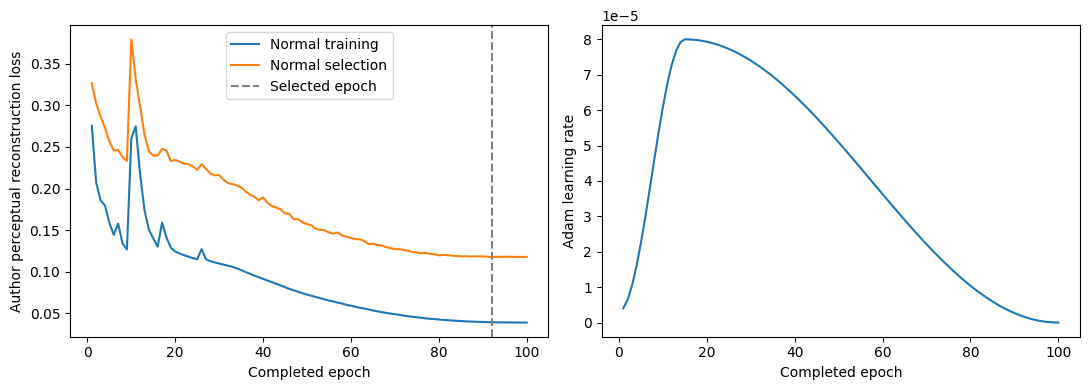

In [7]:
def capture_rng():
    n = np.random.get_state()
    return dict(python=random.getstate(), numpy=(n[0], n[1].tolist(), n[2], n[3], n[4]),
                torch=torch.get_rng_state(), cuda=torch.cuda.get_rng_state_all())

def restore_rng(r):
    random.setstate(r['python'])
    n = r['numpy']; np.random.set_state((n[0], np.asarray(n[1], dtype=np.uint32), n[2], n[3], n[4]))
    torch.set_rng_state(r['torch']); torch.cuda.set_rng_state_all(r['cuda'])

def cpu_reconstruction_state():
    # Frozen pretrained backbone is stored ONCE in frozen_backbones.pt.
    return {k: v.detach().cpu().clone() for k, v in model.state_dict().items()
            if not k.startswith('encoders.0.model.')}

def restore_reconstruction_state(state):
    result = model.load_state_dict(state, strict=False)
    if result.unexpected_keys or any(not k.startswith('encoders.0.model.') for k in result.missing_keys):
        raise RuntimeError('Incomplete or incompatible QFAE reconstruction state: '+str(result))

def optimizer_to_device(opt):
    for state in opt.state.values():
        for key, value in state.items():
            if torch.is_tensor(value): state[key] = value.to(DEVICE)

def meaningful_improvement(value, anchor):
    return anchor is None or anchor-value > max(MIN_ABS, MIN_RELATIVE*abs(anchor))

def new_training_cursor():
    return dict(completed=0, validated_epochs=0, best_epoch=0, best_loss=None,
        anchor=None, stale=0, epoch=1, stage='train', next_group=0,
        train_loss_sum=0.0, train_count=0, train_seconds=0.0,
        select_next=0, select_loss_sum=0.0, select_count=0, select_seconds=0.0,
        training_image_presentations=0, complete=False, stop_reason=None,
        skipped_amp_updates=0, history=[])

trainable = [p for p in model.parameters() if p.requires_grad]
optimizer = torch.optim.Adam(trainable, lr=LR, betas=(.9,.999), eps=1e-8, weight_decay=0.0)
scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=LR,
    total_steps=MAX_EPOCHS*STEPS_PER_EPOCH, pct_start=.15)
scaler = torch.amp.GradScaler('cuda', enabled=USE_AMP)
stats = new_training_cursor()

def checkpoint_last():
    # No live accumulation is saved: every cursor is an effective-batch boundary.
    payload = dict(schema=1, config_sha256=digest(config), source_commit=SOURCE_COMMIT,
        frozen_sha256=FROZEN_SHA, reconstruction=cpu_reconstruction_state(),
        optimizer=optimizer.state_dict(), scheduler=scheduler.state_dict(),
        scaler=scaler.state_dict(), cursor=stats, rng=capture_rng())
    save_pt(payload, RUN/'last.pt')
    pd.DataFrame(stats['history']).to_csv(RUN/'training_history.csv', index=False)
    write_json(RUN/'status.json', dict(status='complete_training' if stats['complete'] else 'training',
        stage=stats['stage'], completed_epochs=stats['validated_epochs'],
        selected_epoch=stats['best_epoch'], optimizer_steps=stats['completed'],
        partial_epoch=stats['epoch'], next_effective_batch=stats['next_group'],
        next_selection_image=stats['select_next'], stale=stats['stale'], max_epochs=MAX_EPOCHS,
        stop_reason=stats['stop_reason'], test_evaluated=False,
        training_image_presentations=stats['training_image_presentations']))

if (RUN/'last.pt').is_file():
    payload = load_pt(RUN/'last.pt')
    if payload['config_sha256'] != digest(config) or payload['frozen_sha256'] != FROZEN_SHA:
        raise RuntimeError('Checkpoint/config/frozen backbone mismatch; do not start a fresh run to recover.')
    restore_reconstruction_state(payload['reconstruction'])
    optimizer.load_state_dict(payload['optimizer']); optimizer_to_device(optimizer)
    scheduler.load_state_dict(payload['scheduler']); scaler.load_state_dict(payload['scaler'])
    stats = payload['cursor']; restore_rng(payload['rng'])
    del payload
    if stats['validated_epochs'] and not (RUN/'best.pt').is_file():
        raise FileNotFoundError('Recovery needs best.pt too. Attach the complete previous output.')
    print(f"Recovered {stats['validated_epochs']} validated epochs, selected {stats['best_epoch']}, "
          f"updates {stats['completed']}; epoch {stats['epoch']} / {stats['stage']}, "
          f"next effective batch {stats['next_group']}, next select image {stats['select_next']}.")
elif MODE == 'resume' or MODE == 'evaluate':
    raise FileNotFoundError(RUN/'last.pt')
else:
    checkpoint_last()

def train_to_policy_completion():
    if CACHE_FROZEN_DINO and not stats['complete']:
        ensure_dino_cache('train'); ensure_dino_cache('select')
    while not stats['complete']:
        epoch = stats['epoch']
        if stats['stage'] == 'train':
            freeze_and_mode(model, True)
            loader = training_loader(epoch, stats['next_group'])
            for group_indices, inp in loader:
                check_session_time()
                group_start = time.monotonic()
                size = len(inp)
                group_rng=capture_rng()
                for attempt in range(11):
                    # Overflow retries repeat exactly the SAME effective batch and RNG.
                    restore_rng(group_rng); check_session_time()
                    optimizer.zero_grad(set_to_none=True)
                    group_loss_sum=0.0
                    for begin in range(0,size,MICRO_BATCH):
                        part=inp[begin:begin+MICRO_BATCH].to(DEVICE,non_blocking=True)
                        ids=group_indices[begin:begin+MICRO_BATCH]
                        with torch.autocast('cuda',dtype=torch.float16,enabled=USE_AMP):
                            reconstruction=reconstruction_for(part,'train',ids)
                            loss=perceptual.training_maps(part,reconstruction).mean()
                        if not bool(torch.isfinite(loss)):
                            raise FloatingPointError(f'Nonfinite training loss at epoch {epoch}.')
                        scaler.scale(loss*(len(part)/size)).backward()
                        group_loss_sum+=float(loss.detach())*len(part)
                        del part,reconstruction,loss
                    old_scale=scaler.get_scale()
                    scaler.step(optimizer); scaler.update()
                    skipped=USE_AMP and scaler.get_scale()<old_scale
                    if not skipped: break
                    stats['skipped_amp_updates']+=1
                    optimizer.zero_grad(set_to_none=True)
                    restore_rng(group_rng)
                    print('AMP overflow: retrying the same effective batch at scale',scaler.get_scale(),flush=True)
                else:
                    checkpoint_last()
                    raise FloatingPointError('Persistent AMP overflow after11 tries. Cursor saved before this batch; '
                        'no optimizer/scheduler clock was advanced for failed attempts.')
                scheduler.step()
                optimizer.zero_grad(set_to_none=True)
                stats['completed'] += 1; stats['next_group'] += 1
                stats['train_loss_sum'] += group_loss_sum; stats['train_count'] += size
                stats['training_image_presentations'] += size
                stats['train_seconds'] += time.monotonic()-group_start
                if stats['completed'] % SAVE_EVERY_UPDATES == 0:
                    checkpoint_last()
            if stats['next_group'] != STEPS_PER_EPOCH or stats['train_count'] != len(splits['train']):
                raise RuntimeError('An epoch did not cover every training frame exactly once.')
            stats['stage'] = 'select'
            checkpoint_last()
        if stats['stage'] == 'select':
            freeze_and_mode(model, False)
            with torch.no_grad():
                for indices, inp in clean_loader('select', start=stats['select_next']):
                    check_session_time()
                    begin_time = time.monotonic()
                    inp = inp.to(DEVICE, non_blocking=True)
                    with torch.autocast('cuda', dtype=torch.float16, enabled=USE_AMP):
                        reconstruction = reconstruction_for(inp, 'select', indices)
                        values = perceptual.normal_selection_score(inp, reconstruction)
                    if not bool(torch.isfinite(values).all()): raise FloatingPointError('Nonfinite normal selection loss.')
                    stats['select_loss_sum'] += float(values.sum())
                    stats['select_count'] += len(inp)
                    stats['select_next'] += len(inp)
                    stats['select_seconds'] += time.monotonic()-begin_time
                    if stats['select_next'] % (EVAL_BATCH*20) == 0: checkpoint_last()
            if stats['select_count'] != len(splits['select']): raise RuntimeError('Incomplete normal-selection pass.')
            normal = stats['select_loss_sum']/stats['select_count']
            train = stats['train_loss_sum']/stats['train_count']
            if meaningful_improvement(normal, stats['anchor']):
                stats['anchor'] = normal; stats['stale'] = 0
            else:
                stats['stale'] += 1
            if stats['best_loss'] is None or normal < stats['best_loss']:
                stats['best_loss'] = normal; stats['best_epoch'] = epoch
                save_pt(dict(schema=1, config_sha256=digest(config), frozen_sha256=FROZEN_SHA,
                    epoch=epoch, normal_loss=normal, completed=stats['completed'],
                    reconstruction=cpu_reconstruction_state()), RUN/'best.pt')
            stats['validated_epochs'] = epoch
            stats['history'].append(dict(epoch=epoch, train_loss=train, normal_select_loss=normal,
                best_epoch=stats['best_epoch'], best_normal_loss=stats['best_loss'],
                patience_anchor=stats['anchor'], stale=stats['stale'], lr=scheduler.get_last_lr()[0],
                optimizer_steps=stats['completed'], training_image_presentations=stats['training_image_presentations'],
                training_seconds=stats['train_seconds'], validation_seconds=stats['select_seconds']))
            duration = stats['train_seconds']+stats['select_seconds']
            print(f"Epoch {epoch}/{MAX_EPOCHS}: train={train:.7f}, normal={normal:.7f}, "
                  f"bestepoch={stats['best_epoch']}, stale={stats['stale']}, seconds={duration:.1f}", flush=True)
            print(f"Estimated training/selection to cap {(MAX_EPOCHS-epoch)*duration/3600:.2f} hours; "
                  'early stopping may finish sooner; calibration/test time is additional.', flush=True)
            if stats['stale'] >= PATIENCE or epoch >= MAX_EPOCHS:
                stats['complete'] = True
                stats['stop_reason'] = 'normal_patience' if stats['stale'] >= PATIENCE else 'maximum_epoch_cap'
                stats['stage'] = 'complete'
            else:
                stats.update(epoch=epoch+1, stage='train', next_group=0,
                    train_loss_sum=0.0, train_count=0, train_seconds=0.0,
                    select_next=0, select_loss_sum=0.0, select_count=0, select_seconds=0.0)
            checkpoint_last()
    return True

TRAINING_COMPLETE = stats['complete']
try:
    if MODE == 'evaluate' and not TRAINING_COMPLETE:
        raise RuntimeError('Training is paused, not complete. Use MODE="resume"; test evaluation stays locked.')
    TRAINING_COMPLETE = train_to_policy_completion()
except SessionPause as exc:
    checkpoint_last()
    write_json(RUN/'status.json', dict(status='paused_for_resume', stage=stats['stage'],
        completed_epochs=stats['validated_epochs'], selected_epoch=stats['best_epoch'],
        partial_epoch=stats['epoch'], next_effective_batch=stats['next_group'],
        next_selection_image=stats['select_next'], optimizer_steps=stats['completed'],
        stale=stats['stale'], max_epochs=MAX_EPOCHS, test_evaluated=False, reason=str(exc)))
    print('Safely paused. Retain the FULL output and resume; no test evaluation during unfinished training.')
    TRAINING_COMPLETE = False

if TRAINING_COMPLETE:
    selected = load_pt(RUN/'best.pt')
    restore_reconstruction_state(selected['reconstruction']); del selected
    freeze_and_mode(model, False)
    print('Training policy complete:', stats['stop_reason'], '| evaluating normal-selected epoch', stats['best_epoch'])

history_df = pd.DataFrame(stats['history'])
if len(history_df):
    fig, axes = plt.subplots(1,2,figsize=(11,4))
    axes[0].plot(history_df.epoch, history_df.train_loss, label='Normal training')
    axes[0].plot(history_df.epoch, history_df.normal_select_loss, label='Normal selection')
    axes[0].axvline(stats['best_epoch'], color='gray', linestyle='--', label='Selected epoch')
    axes[0].set(xlabel='Completed epoch',ylabel='Author perceptual reconstruction loss'); axes[0].legend()
    axes[1].plot(history_df.epoch, history_df.lr); axes[1].set(xlabel='Completed epoch',ylabel='Adam learning rate')
    fig.tight_layout(); fig.savefig(RUN/'training_curves.png',dpi=150); plt.show()


## Thresholds, masks and standardized metrics

- Historical: threshold Q3 + 4·IQR of all normal select/calibrate/audit pixels, as previously.
- FPR comparisons: thresholds from 4,096 sampled pixels per calibration frame; fixed seed, quantile `higher`, targets 0.005, 0.01, 0.02, 0.05, 0.10. Independent audit frames measure achieved FPR.
- Same morphology: 3×3 closing twice → opening once → fill holes → remove four-connected components smaller than 50 pixels → opening twice.
- Masks: grayscale bilinear resize to 256, foreground >0.5, only after the model and threshold lock.

**Main metric: `mean_frame_iou`**, the arithmetic mean of foreground IoU over the fixed 496 test frames. `mean_iou` is its exact alias. `pooled_iou` pools pixel counts and is a different statistic. The report also retains per-frame/pooled Dice, precision and recall; exact full-pixel AP, AUROC and normalized AUPRO up to FPR 0.30; raw/postprocessed results; per-video results and fixed example images. Image AP/AUROC are left undefined if the test images contain only one class; extra audit negatives are not inserted into the test set.

Historical and normal-FPR results are not interchangeable. Compare the same `score / protocol / processing` row across methods. For our historical RGB reconstruction comparison, use `shared_mae / historical / postprocessed / mean_frame_iou`; show the native QFAE row alongside it.


In [8]:
"""WS2 evaluation functions; call only after the normal-only policy is complete.

Executed in the notebook's shared namespace. Dataset membership, preprocessing,
model construction, score_batch and checkpoint selection belong to the runner.
The protocol below follows the existing max100 WS2 baseline notebooks.
"""

import json
import time
from pathlib import Path
import numpy as np
import pandas as pd
from PIL import Image
from scipy.ndimage import (generate_binary_structure, binary_closing,
                           binary_opening, binary_fill_holes, label)
from sklearn.metrics import average_precision_score, roc_auc_score
import matplotlib.pyplot as plt
from tqdm.auto import tqdm


def postprocess(mask):
    struct = generate_binary_structure(2, 2)
    m = binary_closing(mask, structure=struct, iterations=2)
    m = binary_opening(m, structure=struct, iterations=1)
    m = binary_fill_holes(m)
    cc, _ = label(m)
    keep = np.bincount(cc.ravel()) >= 50
    keep[0] = False
    return binary_opening(keep[cc], structure=struct, iterations=2)


def confusion(pred, target):
    return (int(np.count_nonzero(pred & target)), int(np.count_nonzero(pred & ~target)),
            int(np.count_nonzero(~pred & target)), int(np.count_nonzero(~pred & ~target)))


def iou(tp, fp, fn):
    return tp / (tp + fp + fn) if tp + fp + fn else 1.0


def dice(tp, fp, fn):
    return 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else 1.0


def pixel_ranking(scores, masks):
    # Exact AP/AUROC, with tied scores grouped, using a single sorting pass.
    # PRO weights every 8-connected GT region equally; integrate FPR<=0.30.
    y = np.asarray(masks, dtype=np.bool_).ravel()
    score = np.asarray(scores, dtype=np.float32).ravel()
    positives, negatives = int(y.sum()), int((~y).sum())
    if positives == 0 or negatives == 0:
        return dict(pixel_ap=None, pixel_auroc=None, pixel_aupro_0p30=None,
                    gt_regions=0, positive_pixels=positives, negative_pixels=negatives)
    weights = np.zeros(masks.shape, dtype=np.float32)
    regions = 0
    struct = generate_binary_structure(2, 2)
    for i, m in enumerate(masks):
        cc, n = label(m, structure=struct)
        areas = np.bincount(cc.ravel())
        lookup = np.zeros(len(areas), dtype=np.float32)
        lookup[1:] = 1. / areas[1:]
        weights[i] = lookup[cc]
        regions += n
    order = np.argsort(score, kind='stable')[::-1]
    sorted_scores = score[order]
    ends = np.r_[np.flatnonzero(np.diff(sorted_scores)), len(score) - 1]
    del sorted_scores
    cumsum = np.cumsum(y[order], dtype=np.int64)
    tp = cumsum[ends].astype(np.float64)
    del cumsum
    fp = (ends + 1).astype(np.float64) - tp
    ap = float(np.sum(np.diff(np.r_[0., tp]) * (tp / (ends + 1))) / positives)
    fpr = np.r_[0., fp / negatives]
    tpr = np.r_[0., tp / positives]
    trapz = getattr(np, 'trapezoid', None) or np.trapz
    auroc = float(trapz(tpr, fpr))
    del tp, fp, tpr
    region_cumsum = np.cumsum(weights.ravel()[order], dtype=np.float64)
    pro = np.r_[0., region_cumsum[ends] / regions]
    del region_cumsum, weights, order, ends
    cap = .30
    right = int(np.searchsorted(fpr, cap, side='right'))
    xx, yy = fpr[:right], pro[:right]
    if xx[-1] < cap:
        endpoint = yy[-1] + (pro[right] - yy[-1]) * (cap - xx[-1]) / (fpr[right] - xx[-1])
        xx = np.r_[xx, cap]
        yy = np.r_[yy, endpoint]
    aupro = float(trapz(yy, xx) / cap)
    return dict(pixel_ap=ap, pixel_auroc=auroc, pixel_aupro_0p30=aupro,
                gt_regions=int(regions), positive_pixels=positives, negative_pixels=negatives)


def _numpy(value, dtype=None):
    if hasattr(value, 'detach'):
        value = value.detach().cpu().numpy()
    return np.asarray(value, dtype=dtype)


def _score_cache_dir():
    p = CACHE / ('scores_' + sha(RUN / 'best.pt')[:16])
    p.mkdir(parents=True, exist_ok=True)
    return p


def _assert_evaluation_allowed():
    if not TRAINING_COMPLETE:
        raise RuntimeError('Test evaluation requires a completed training policy, not a session pause.')
    lock = json.loads((RUN / 'evaluation_lock.json').read_text())
    if lock['config_sha256'] != digest(config):
        raise RuntimeError('Evaluation config differs from the normal-only lock.')
    if lock['checkpoint_sha256'] != sha(RUN / 'best.pt'):
        raise RuntimeError('Evaluation checkpoint differs from the normal-only lock.')
    if lock['thresholds_sha256'] != sha(RUN / 'thresholds_LOCKED.json'):
        raise RuntimeError('Evaluation thresholds differ from the normal-only lock.')
    return lock


def score_maps(role):
    """Resume after committed frames; flush every map before advancing its cursor."""
    if role not in splits:
        raise ValueError(role)
    if role == 'test':
        _assert_evaluation_allowed()
    model.eval()
    if hasattr(perceptual, 'eval'):
        perceptual.eval()
    folder = _score_cache_dir()
    cursor_path = folder / f'{role}.cursor.json'
    shape = (len(splits[role]), SIZE, SIZE)
    cfg_hash, best_hash = digest(config), sha(RUN / 'best.pt')
    paths = {s: folder / f'{s}_{role}.npy' for s in SCORES}
    image_paths = {s: folder / f'{s}_{role}_image.npy' for s in SCORES}
    if cursor_path.exists():
        stamp = json.loads(cursor_path.read_text())
        if (stamp['config_sha256'] != cfg_hash or stamp['checkpoint_sha256'] != best_hash
                or stamp['total_frames'] != shape[0] or stamp['scores'] != list(SCORES)):
            raise RuntimeError('Foreign or incompatible score-cache cursor.')
        done = int(stamp['completed_frames'])
        if not 0 <= done <= shape[0]:
            raise RuntimeError('Invalid score-cache frame cursor.')
        arrays = {s: np.load(paths[s], mmap_mode='r+') for s in SCORES}
        image_arrays = {s: np.load(image_paths[s], mmap_mode='r+') for s in SCORES}
        available = stamp['image_score_available']
        seconds = float(stamp.get('scoring_seconds', 0.))
    else:
        done, seconds = 0, 0.
        available = {s: None for s in SCORES}
        arrays = {s: np.lib.format.open_memmap(paths[s], mode='w+', dtype=np.float32,
                                              shape=shape) for s in SCORES}
        image_arrays = {s: np.lib.format.open_memmap(image_paths[s], mode='w+',
                                                   dtype=np.float64, shape=(shape[0],))
                        for s in SCORES}
        for a in image_arrays.values():
            a[:] = np.nan
    for a in arrays.values():
        if a.shape != shape or a.dtype != np.float32:
            raise RuntimeError('Invalid cached score-map shape or dtype.')
    for a in image_arrays.values():
        if a.shape != (shape[0],) or a.dtype != np.float64:
            raise RuntimeError('Invalid cached image-score shape or dtype.')

    def commit():
        for a in list(arrays.values()) + list(image_arrays.values()):
            a.flush()
        write_json(cursor_path, dict(completed_frames=done, total_frames=shape[0],
            scores=list(SCORES), config_sha256=cfg_hash, checkpoint_sha256=best_hash,
            image_score_available=available, scoring_seconds=seconds))

    commit()
    rgb_cache = cache_images(role) if done < shape[0] else None
    try:
        for indices, inp in tqdm(clean_loader(role, start=done), desc='Score ' + role,
                                 disable=done == shape[0]):
            check_session_time()
            begin = time.monotonic()
            index = _numpy(indices, np.int64).reshape(-1)
            if len(index) == 0 or not np.array_equal(index, np.arange(done, done + len(index))):
                raise RuntimeError('Evaluation loader must preserve exact sequential record order.')
            rgb = np.asarray(rgb_cache[index], dtype=np.uint8)
            result = score_batch(inp.to(DEVICE, non_blocking=True), rgb)
            if isinstance(result, tuple):
                batch_maps, batch_images = result
                batch_images = batch_images or {}
            else:
                batch_maps, batch_images = result, {}
            if set(batch_maps) != set(SCORES):
                raise RuntimeError('score_batch must return exactly the configured score maps.')
            for s in SCORES:
                value = _numpy(batch_maps[s], np.float32)
                if value.shape != (len(index), SIZE, SIZE) or not np.isfinite(value).all():
                    raise FloatingPointError('Invalid shape or nonfinite map: ' + s)
                arrays[s][index] = value
                if s in batch_images:
                    image_value = _numpy(batch_images[s], np.float64).reshape(-1)
                    has_image = True
                elif s == 'shared_mae':
                    flat = value.reshape(len(index), -1)
                    k = max(1, int(flat.shape[1] * .01))
                    image_value = np.partition(flat, flat.shape[1] - k, axis=1)[:, -k:].mean(1)
                    has_image = True
                else:
                    image_value, has_image = np.full(len(index), np.nan), False
                if available[s] is not None and bool(available[s]) != has_image:
                    raise RuntimeError('Image-score contract changed between batches: ' + s)
                available[s] = has_image
                if has_image and (image_value.shape != (len(index),) or not np.isfinite(image_value).all()):
                    raise FloatingPointError('Invalid image scores: ' + s)
                image_arrays[s][index] = image_value
            done += len(index)
            seconds += time.monotonic() - begin
            commit()
            del result, inp
    finally:
        commit()
    if done != shape[0]:
        raise RuntimeError('Score loader ended before every frame was committed.')
    write_json(RUN / f'scoring_runtime_{role}.json', dict(frames=done, seconds=seconds,
        description='Accumulated score_batch, RGB fetch, conversion and map-write time; '
                    'excludes image-cache creation, DataLoader waiting and cursor flushing. '
                    'This is not isolated GPU latency.'))
    output = {s: np.load(paths[s], mmap_mode='r') for s in SCORES}
    for s, arr in output.items():
        if not all(np.isfinite(a).all() for a in arr):
            raise FloatingPointError('Nonfinite cached map: ' + s)
        if available[s] and not np.isfinite(image_arrays[s]).all():
            raise FloatingPointError('Nonfinite cached image scores: ' + s)
    return output


def calibrate_scores():
    if not TRAINING_COMPLETE:
        raise RuntimeError('Calibration requires completion of the normal-only training policy.')
    maps = {role: score_maps(role) for role in ('select', 'calibrate', 'audit')}
    thresholds, rows = {}, []
    for s in SCORES:
        check_session_time()
        values = np.concatenate([maps[r][s].ravel() for r in ('select', 'calibrate', 'audit')])
        q1, q3 = np.percentile(values, [25, 75])
        thresholds[s] = {'historical': float(q3 + 4 * (q3 - q1))}
        del values
        rng = np.random.default_rng(SEED + 71)
        sample = np.concatenate([a.ravel()[rng.choice(SIZE * SIZE, 4096, replace=False)]
                                 for a in maps['calibrate'][s]])
        for f in FPRS:
            thresholds[s][f'fpr_{f:g}'] = float(np.quantile(sample, 1 - f, method='higher'))
        for protocol, threshold in thresholds[s].items():
            raw, post = [], []
            for a in maps['audit'][s]:
                pred = a > threshold
                raw.append(float(pred.mean()))
                post.append(float(postprocess(pred).mean()))
            rows.append(dict(score=s, protocol=protocol, threshold=threshold,
                audit_raw_fpr=float(np.mean(raw)), audit_post_fpr=float(np.mean(post)),
                audit_used_in_threshold=(protocol == 'historical')))
    write_json(RUN / 'thresholds_LOCKED.json', thresholds)
    audit = pd.DataFrame(rows)
    audit.to_csv(RUN / 'normal_fpr.csv', index=False)
    write_json(RUN / 'evaluation_lock.json', dict(checkpoint_sha256=sha(RUN / 'best.pt'),
        config_sha256=digest(config), thresholds_sha256=sha(RUN / 'thresholds_LOCKED.json'),
        test_masks_decoded=False, checkpoint_selection='normal-only',
        historical_audit_independent=False, quantile_audit_independent=True))
    return maps, thresholds, audit


def _image_ranking(test_maps, gt):
    folder = _score_cache_dir()
    stamp = json.loads((folder / 'test.cursor.json').read_text())
    image_labels = np.asarray([bool(m.any()) for m in gt], dtype=np.int64)
    has_both = len(np.unique(image_labels)) == 2
    rows, rankings = [], []
    for s in SCORES:
        available = bool(stamp['image_score_available'].get(s, False))
        values = np.load(folder / f'{s}_test_image.npy', mmap_mode='r') if available else None
        aggregation = ('Author mean of per-hidden-map spatial maxima' if s == 'qfae_perceptual'
                       else 'Mean of largest 1% of shared RGB error pixels')
        for i, record in enumerate(splits['test']):
            rows.append(dict(score=s, relative=record['relative'], video=record['video'],
                image_score=float(values[i]) if available else None,
                mask_has_anomaly=int(image_labels[i]), aggregation=aggregation))
        valid = has_both and available
        rankings.append(dict(score=s, normal_frames=int((image_labels == 0).sum()),
            anomalous_frames=int((image_labels == 1).sum()), aggregation=aggregation,
            image_ap=float(average_precision_score(image_labels, values)) if valid else None,
            image_auroc=float(roc_auc_score(image_labels, values)) if valid else None,
            note=('Labels from evaluated masks; no test selection' if valid else
                  'Undefined discrimination: test has only one image class' if not has_both else
                  'Unavailable: score_batch did not provide the native image aggregation')))
    pd.DataFrame(rows).to_csv(RUN / 'test_image_scores.csv', index=False)
    write_json(RUN / 'image_ranking.json', rankings)
    return rankings


def evaluate_test(maps, thresholds, audit):
    _assert_evaluation_allowed()
    if thresholds != json.loads((RUN / 'thresholds_LOCKED.json').read_text()):
        raise RuntimeError('In-memory thresholds differ from the saved normal-only evaluation lock.')
    maps['test'] = score_maps('test')
    gt = np.lib.format.open_memmap(CACHE / 'test_masks.npy', mode='w+', dtype=np.bool_,
                                 shape=(len(splits['test']), SIZE, SIZE))
    mask_hashes = []
    for i, record in enumerate(tqdm(splits['test'], desc='Decode masks after evaluation lock')):
        check_session_time()
        with Image.open(record['mask']) as image:
            gt[i] = np.asarray(image.convert('L').resize((SIZE, SIZE), Image.Resampling.BILINEAR),
                               dtype=np.float32) / 255 > .5
        mask_hashes.append(dict(relative=record['relative'], sha256=sha(record['mask'])))
    gt.flush()
    if not gt.any() or gt.all():
        raise RuntimeError('The expected WS2 test masks must contain foreground and background pixels.')
    write_json(RUN / 'mask_hashes.json', mask_hashes)
    rows = []
    for s in SCORES:
        for protocol, threshold in thresholds[s].items():
            check_session_time()
            for i, record in enumerate(splits['test']):
                raw = maps['test'][s][i] > threshold
                for processing, pred in [('raw', raw), ('postprocessed', postprocess(raw))]:
                    tp, fp, fn, tn = confusion(pred, gt[i])
                    rows.append(dict(score=s, protocol=protocol, processing=processing,
                        relative=record['relative'], video=record['video'], tp=tp, fp=fp, fn=fn, tn=tn,
                        iou=iou(tp, fp, fn), dice=dice(tp, fp, fn),
                        precision=tp / (tp + fp) if tp + fp else 0.,
                        recall=tp / (tp + fn) if tp + fn else 0.))
    frames = pd.DataFrame(rows)
    frames.to_csv(RUN / 'test_frame_metrics.csv', index=False)
    keys = ['score', 'protocol', 'processing']
    summaries = []
    for (s, protocol, processing), group in frames.groupby(keys, sort=False):
        tp, fp, fn, tn = [int(group[c].sum()) for c in ('tp', 'fp', 'fn', 'tn')]
        a = audit[(audit.score == s) & (audit.protocol == protocol)].iloc[0]
        summaries.append(dict(model=MODEL_LABEL, score=s, protocol=protocol, processing=processing,
            mean_frame_iou=float(group.iou.mean()), mean_iou=float(group.iou.mean()),
            median_frame_iou=float(group.iou.median()), mean_frame_dice=float(group.dice.mean()),
            mean_frame_precision=float(group.precision.mean()), mean_frame_recall=float(group.recall.mean()),
            pooled_iou=iou(tp, fp, fn), pooled_dice=dice(tp, fp, fn),
            pooled_precision=tp / (tp + fp) if tp + fp else 0.,
            pooled_recall=tp / (tp + fn) if tp + fn else 0.,
            tp=tp, fp=fp, fn=fn, tn=tn, threshold=float(a.threshold),
            audit_raw_fpr=float(a.audit_raw_fpr), audit_post_fpr=float(a.audit_post_fpr),
            audit_used_in_threshold=bool(a.audit_used_in_threshold), n_frames=len(group),
            total_parameters=PARAMETERS, trainable_parameters=TRAINABLE_PARAMETERS,
            frozen_parameters=FROZEN_PARAMETERS, selected_epoch=int(stats['best_epoch']),
            completed_epochs=int(stats['validated_epochs']), max_epochs=100,
            optimizer_steps=int(stats['completed']),
            training_image_presentations=int(stats['training_image_presentations'])))
    summary = pd.DataFrame(summaries)
    summary.to_csv(RUN / 'summary.csv', index=False)
    frames.groupby(keys + ['video'], as_index=False).agg(
        mean_frame_iou=('iou', 'mean'), mean_frame_dice=('dice', 'mean'),
        frames=('iou', 'size')).to_csv(RUN / 'test_video_metrics.csv', index=False)
    rankings = []
    for s in SCORES:
        check_session_time()
        print('Exact full-pixel AP / AUROC / AUPRO:', s, flush=True)
        rankings.append(dict(score=s, **pixel_ranking(maps['test'][s], gt)))
    ranking = pd.DataFrame(rankings)
    ranking.to_csv(RUN / 'full_pixel_ranking.csv', index=False)
    headline = summary[(summary.processing == 'postprocessed') &
                       summary.protocol.isin(['historical', 'fpr_0.02'])].merge(ranking, on='score')
    headline.to_csv(RUN / 'headline_metrics.csv', index=False)
    _image_ranking(maps['test'], gt)
    write_json(RUN / 'evaluation_status.json', dict(status='metrics_complete',
        selected_epoch=int(stats['best_epoch']), completed_epochs=int(stats['validated_epochs']),
        test_frames=len(gt), config_sha256=digest(config), checkpoint_sha256=sha(RUN / 'best.pt'),
        primary_metric='mean_frame_iou; arithmetic mean foreground IoU over the 496 fixed frames',
        protocols='historical and normal-calibration FPR; both scores and raw/postprocessed masks',
        test_masks_used_for='locked evaluation only'))
    print('Main comparison rows: historical / postprocessed / mean_frame_iou, one row per score.')
    if 'display' in globals():
        display(headline[['score', 'protocol', 'selected_epoch', 'completed_epochs',
            'mean_frame_iou', 'mean_frame_dice', 'pooled_precision', 'pooled_recall',
            'pixel_ap', 'pixel_auroc', 'pixel_aupro_0p30', 'audit_post_fpr']])
    return gt, frames, summary, ranking, headline


def plot_results(maps, thresholds, audit, gt, summary, ranking):
    """Fixed evenly spaced frames; plots never select models or thresholds."""
    check_session_time()
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for s in SCORES:
        group = summary[(summary.score == s) & (summary.processing == 'postprocessed') &
                        summary.protocol.str.startswith('fpr_')].sort_values('audit_post_fpr')
        axes[0].plot(group.audit_post_fpr, group.mean_frame_iou, 'o-', label=s)
    axes[0].set(xlabel='Achieved independent normal-audit pixel FPR', ylabel='Mean frame IoU',
                title='Normal-only quantiles; fixed morphology')
    axes[0].legend(fontsize=8)
    axes[1].bar(ranking.score, ranking.pixel_ap)
    axes[1].set(ylabel='Full-pixel average precision', title='Threshold-free comparison')
    axes[1].tick_params(axis='x', labelrotation=20)
    fig.tight_layout()
    fig.savefig(RUN / 'comparison_metrics.png', dpi=150)
    plt.show()
    historical = summary[(summary.protocol == 'historical') &
                         (summary.processing == 'postprocessed')]
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.bar(historical.score, historical.mean_frame_iou)
    for i, value in enumerate(historical.mean_frame_iou):
        ax.text(i, value, f'{value:.5f}', ha='center', va='bottom')
    ax.set(ylabel='Mean frame foreground IoU', title='Historical threshold and morphology')
    fig.tight_layout()
    fig.savefig(RUN / 'historical_mean_frame_iou.png', dpi=150)
    plt.show()

    indices = np.linspace(0, len(splits['test']) - 1, 3, dtype=int)
    rgb = cache_images('test')
    if 'reconstruct_rgb' not in globals():
        raise RuntimeError('Runner must provide reconstruct_rgb(rgb256_uint8_batch) for fixed examples.')
    reconstructed = _numpy(reconstruct_rgb(np.asarray(rgb[indices], dtype=np.uint8)), np.float32)
    if reconstructed.shape == (len(indices), 3, SIZE, SIZE):
        reconstructed = reconstructed.transpose(0, 2, 3, 1)
    if reconstructed.shape != (len(indices), SIZE, SIZE, 3) or not np.isfinite(reconstructed).all():
        raise RuntimeError('Fixed-example reconstruction must be Bx256x256x3 RGB in [0,1].')
    for protocol, filename in [('historical', 'fixed_examples_historical.png'),
                               ('fpr_0.02', 'fixed_examples_normal_fpr_0p02.png')]:
        fig, axes = plt.subplots(len(indices), 7, figsize=(21, 9), squeeze=False)
        for row, i in enumerate(indices):
            axes[row, 0].imshow(rgb[i]); axes[row, 0].set_title('Input')
            axes[row, 1].imshow(gt[i], cmap='gray', vmin=0, vmax=1); axes[row, 1].set_title('Ground truth')
            axes[row, 2].imshow(np.clip(reconstructed[row], 0, 1)); axes[row, 2].set_title('QFAE reconstruction')
            for column, s in [(3, 'shared_mae'), (5, 'qfae_perceptual')]:
                score = maps['test'][s][i]
                axes[row, column].imshow(score, cmap='inferno')
                axes[row, column].set_title(s + ' map')
                axes[row, column + 1].imshow(postprocess(score > thresholds[s][protocol]),
                                             cmap='gray', vmin=0, vmax=1)
                axes[row, column + 1].set_title(s + ' mask')
            for ax in axes[row]:
                ax.axis('off')
        fig.suptitle('Fixed frames; ' + protocol + '; thresholds differ by score')
        fig.tight_layout()
        fig.savefig(RUN / filename, dpi=120)
        plt.show()
    write_json(RUN / 'fixed_examples.json', [splits['test'][int(i)]['relative'] for i in indices])


Score select:   0%|          | 0/261 [00:00<?, ?it/s]

Resize calibrate:   0%|          | 0/128 [00:00<?, ?it/s]

Score calibrate:   0%|          | 0/64 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7d9847602e80>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7d9847602e80>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Resize audit:   0%|          | 0/234 [00:00<?, ?it/s]

...

Resize test:   0%|          | 0/496 [00:00<?, ?it/s]

Score test:   0%|          | 0/248 [00:00<?, ?it/s]

Decode masks after evaluation lock:   0%|          | 0/496 [00:00<?, ?it/s]

Exact full-pixel AP / AUROC / AUPRO: shared_mae
Exact full-pixel AP / AUROC / AUPRO: qfae_perceptual
Main comparison rows: historical / postprocessed / mean_frame_iou, one row per score.


,score,protocol,selected_epoch,completed_epochs,mean_frame_iou,mean_frame_dice,pooled_precision,pooled_recall,pixel_ap,pixel_auroc,pixel_aupro_0p30,audit_post_fpr
0,shared_mae,historical,92,100,0.276712,0.426457,0.420500,0.468099,0.418439,0.755562,0.440456,0.048956
1,shared_mae,fpr_0.02,92,100,0.236197,0.373262,0.534263,0.299062,0.418439,0.755562,0.440456,0.023226
2,qfae_perceptual,historical,92,100,0.088799,0.151586,0.415712,0.118425,0.307853,0.741172,0.330499,0.000650
3,qfae_perceptual,fpr_0.02,92,100,0.212537,0.343401,0.233110,0.786387,0.307853,0.741172,0.330499,0.049382


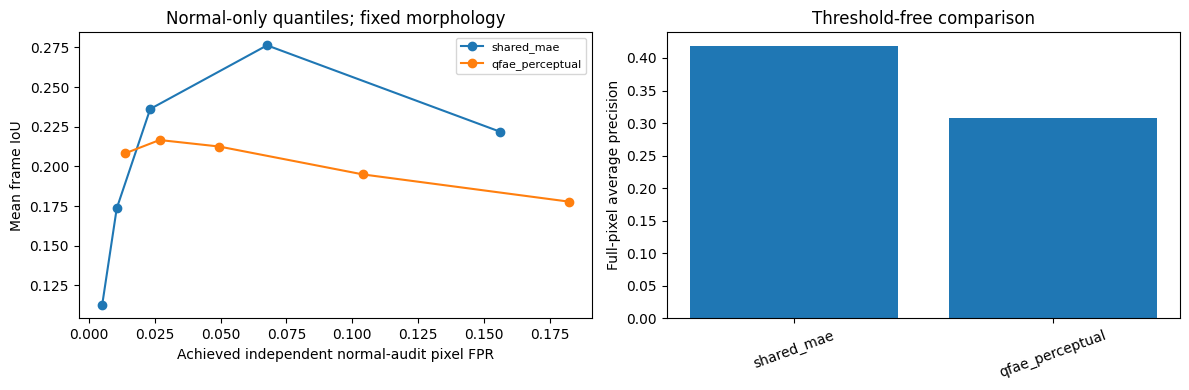

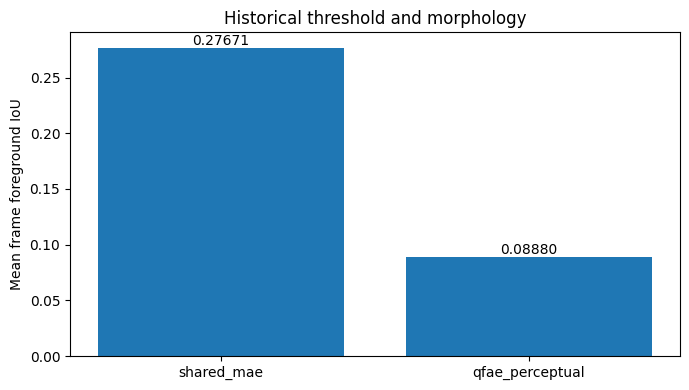

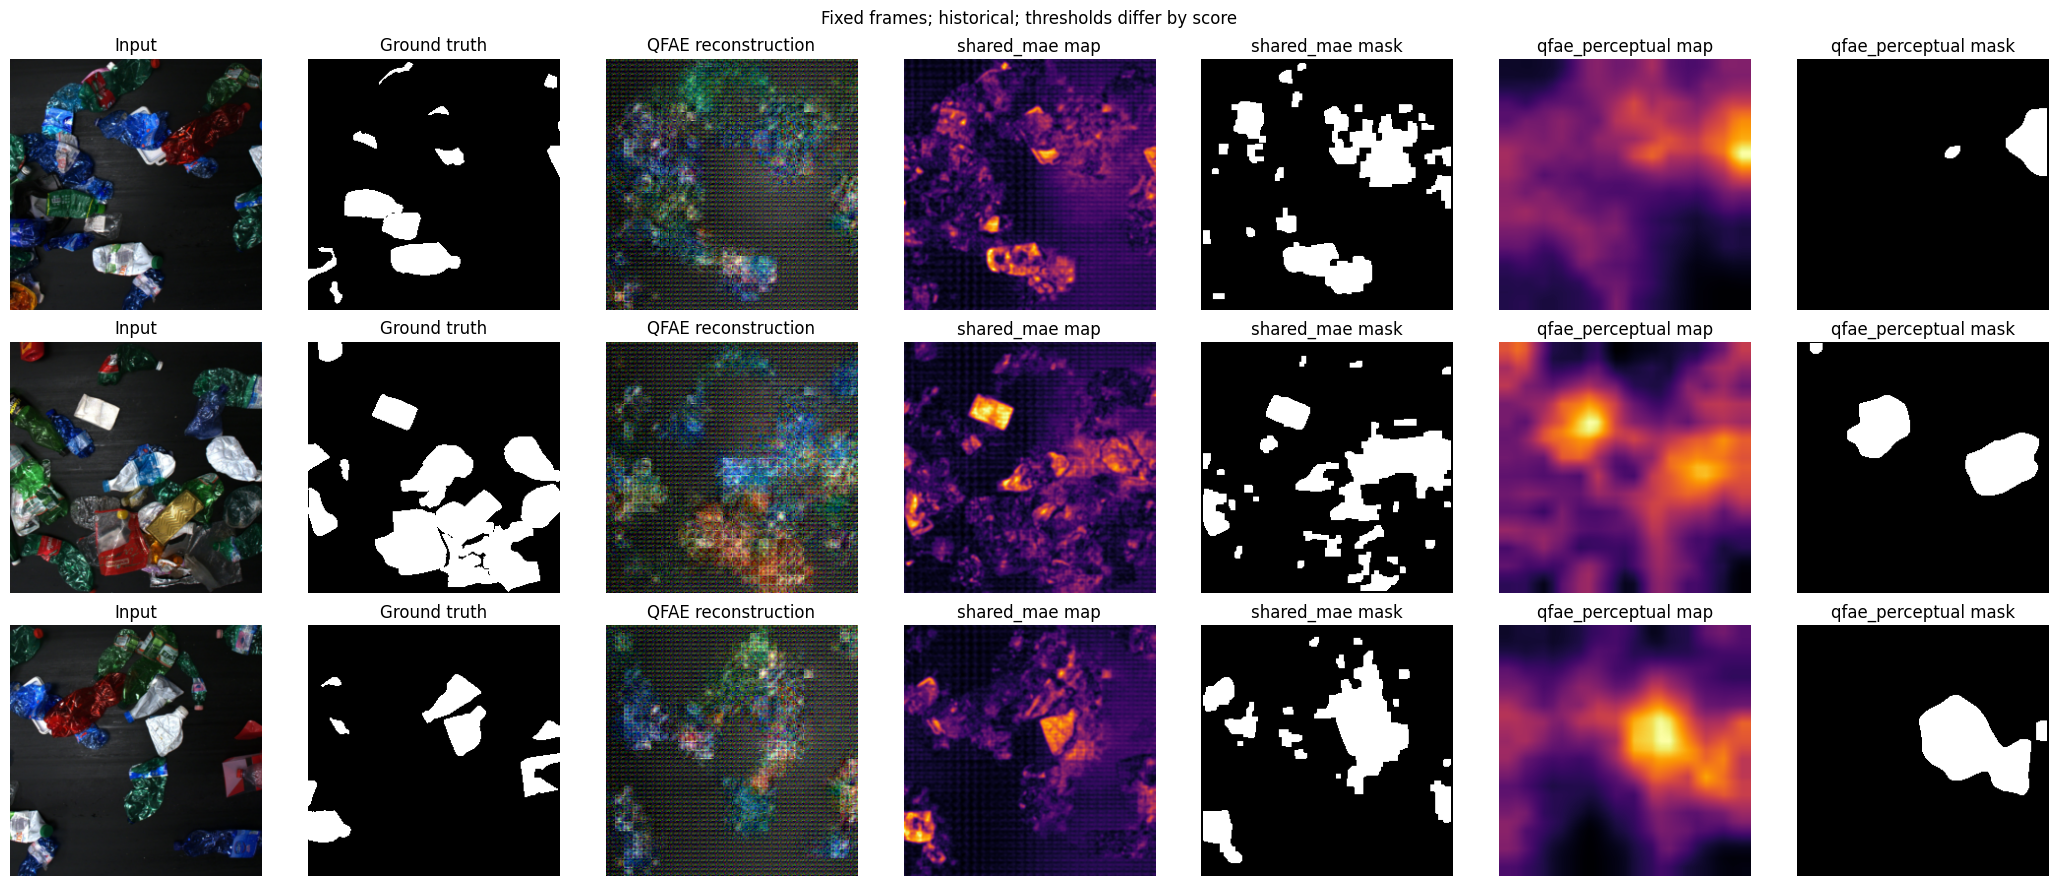

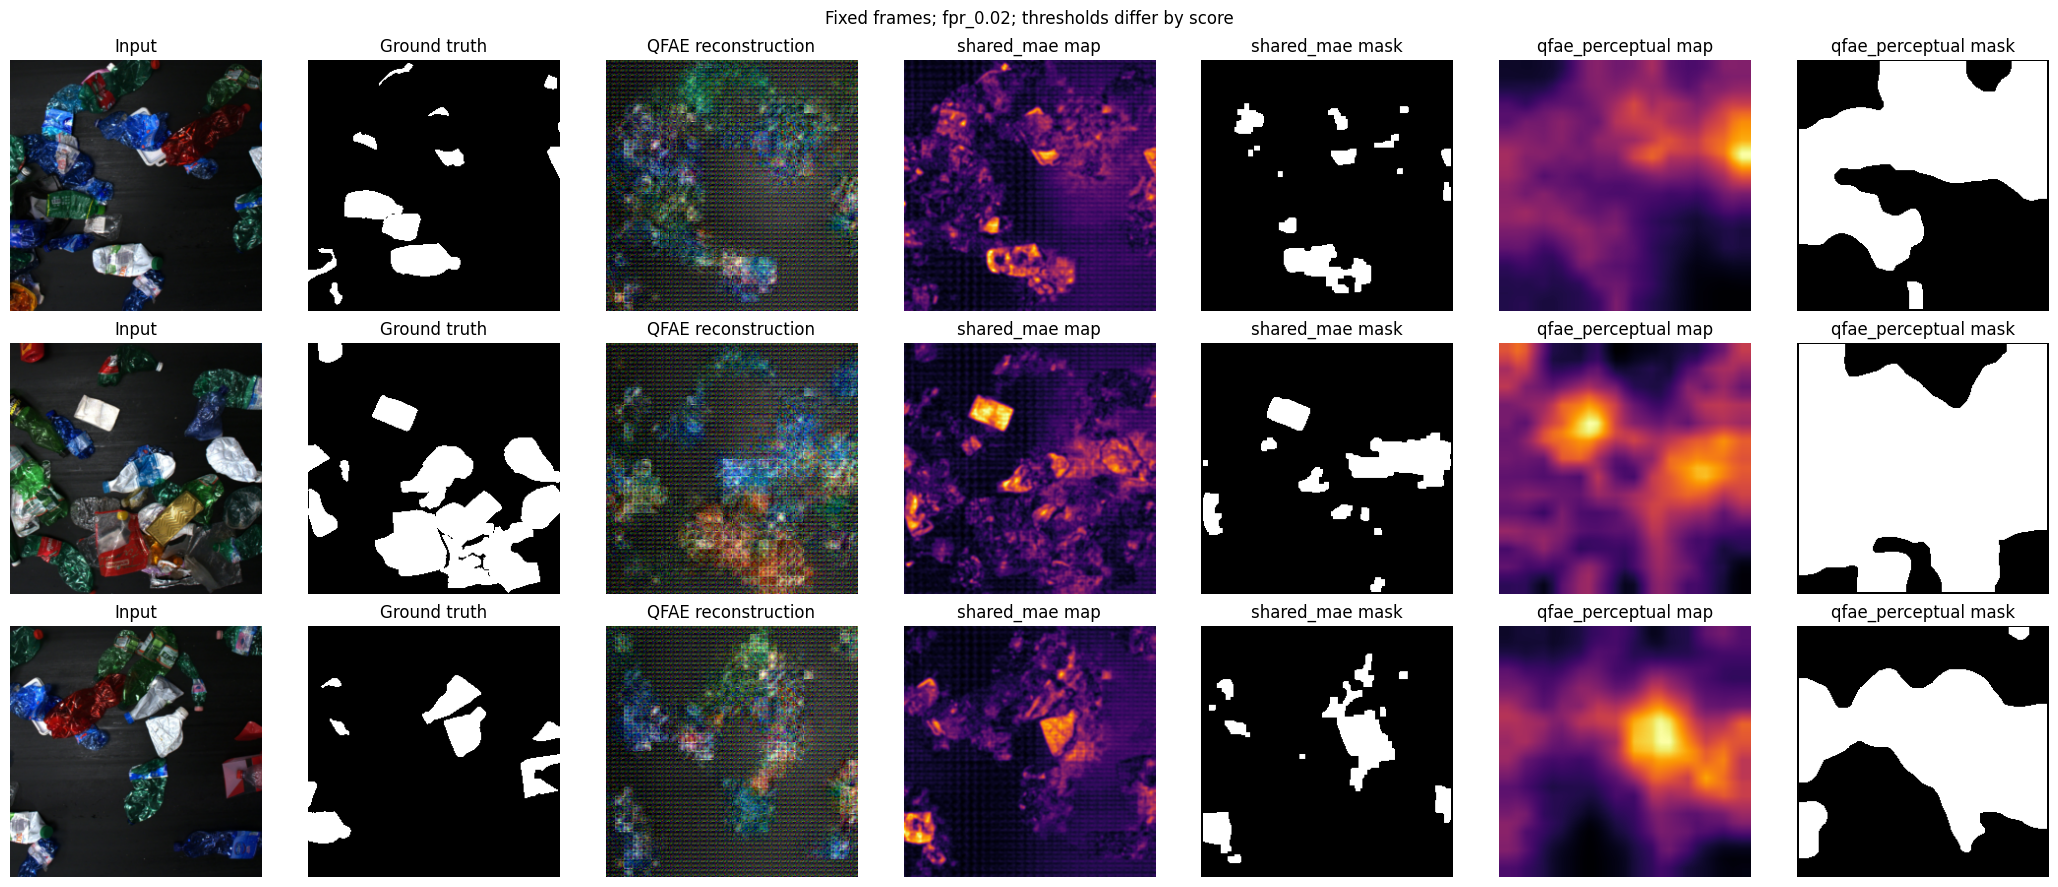

Complete: both score maps, standardized tables and fixed plots saved.


In [9]:
EVALUATION_COMPLETE=False
if TRAINING_COMPLETE:
    try:
        check_session_time()
        maps,thresholds,audit=calibrate_scores()
        gt,frames,summary,ranking,headline=evaluate_test(maps,thresholds,audit)
        plot_results(maps,thresholds,audit,gt,summary,ranking)
        EVALUATION_COMPLETE=True
        write_json(RUN/'status.json',dict(status='complete',completed_epochs=stats['validated_epochs'],
            selected_epoch=stats['best_epoch'],optimizer_steps=stats['completed'],
            stop_reason=stats['stop_reason'],max_epochs=MAX_EPOCHS,test_evaluated=True,
            checkpoint_sha256=sha(RUN/'best.pt'),config_sha256=digest(config)))
        print('Complete: both score maps, standardized tables and fixed plots saved.')
    except SessionPause as exc:
        write_json(RUN/'evaluation_status.json',dict(status='paused_for_resume',training_complete=True,
            selected_epoch=stats['best_epoch'],completed_epochs=stats['validated_epochs'],reason=str(exc),
            next_action='Attach newest FULL output; MODE=resume or evaluate. Preserve _cache to avoid repeated scoring.'))
        print('Evaluation safely paused; trained weights are preserved. Resume from this full output.')
else:
    print('Evaluation skipped: training policy is unfinished. Retain checkpoints and resume.')


## Outputs to send back

Send **`QFAE_baseline_10_report.zip` and the notebook log**. The ZIP includes configs, hashes, training history, parameter/budget records, metrics and plots; it excludes weights and large `.npy` caches.

After a completed run, the key report files are:

- `headline_metrics.csv`: historical and normal-FPR 0.02, postprocessed, both score types, including mean frame IoU and pixel ranking metrics.
- `summary.csv`: all thresholds and raw/postprocessed metrics; `full_pixel_ranking.csv`; `normal_fpr.csv`.
- `training_history.csv`, `comparison_budget.json`, `parameter_counts.json`, `status.json`.
- `test_frame_metrics.csv`, `test_video_metrics.csv`, `image_ranking.json` and the fixed-example/metric plots.

For recovery **retain the full output directory**, particularly `config.json`, `last.pt`, `best.pt` (once validation exists), `frozen_backbones.pt`, and `_cache` if available. Do not upload only the compact report as a recovery input. `MAKE_LARGE_RESUME_ZIP=True` is optional packaging and duplicates several gigabytes; normally leave it False and attach the committed full output.

This notebook does not overwrite Christian, QMem, repair or other baseline outputs. A favourable result cannot be assumed before running it.


In [10]:
notes = {
    'model':'Baseline10 QFAE WACV2026 author WS2 adaptation; replaces unavailable MaskAD',
    'source_commit':SOURCE_COMMIT,
    'training_complete':bool(TRAINING_COMPLETE),
    'evaluation_complete':bool(EVALUATION_COMPLETE),
    'completed_epochs':int(stats['validated_epochs']),
    'selected_epoch':int(stats['best_epoch']),
    'optimizer_steps':int(stats['completed']),
    'training_image_presentations':int(stats['training_image_presentations']),
    'max_epochs':100,'patience':10,
    'external_pretraining':True,'capacity_matched':False,
    'model_parameters':counts,
    'selection':'normal-only mean author image score; strictly lowest checkpoint, separate patience anchor',
    'scores':list(SCORES),
    'primary_historical_comparison':'shared_mae / historical / postprocessed / mean_frame_iou',
    'native_score_reported':'qfae_perceptual; retain separately and show alongside shared RGB result',
    'local_validation':'Author-equivalent CPU fixture forward/gradients, cache and training/validation recovery, metrics tests; no full pretrained local GPU run',
    'real_device_validation':'Notebook full-width GPU shape/finite-map/gradient/memory preflight before optimizer updates',
    'recovery':'Attach newest full output, use MODE=resume; compact report excludes weights',
    'approximate_frozen_feature_cache_bytes':4350*522*1024*(2 if USE_AMP else 4),
}
write_json(RUN/'run_report.json',notes)
write_json(RUN/'memory.json',dict(peak_allocated_bytes=torch.cuda.max_memory_allocated(),
    peak_reserved_bytes=torch.cuda.max_memory_reserved(),device=torch.cuda.get_device_name(0),
    note='Peak since model-setup reset; includes training/scoring in this session, not isolated inference latency.'))
compact = report_zip()
print('SEND: compact report ZIP + complete notebook log. KEEP: full output for recovery.')
print('Full run folder:',RUN)
print('Training complete:',TRAINING_COMPLETE,'| evaluation complete:',EVALUATION_COMPLETE)
display(FileLink(str(compact)))
if MAKE_LARGE_RESUME_ZIP:
    large=RUN.parent/'QFAE_baseline_10_full_resume.zip'
    with zipfile.ZipFile(large,'w',zipfile.ZIP_STORED,allowZip64=True) as archive:
        for path in sorted(RUN.rglob('*')):
            if path.is_file() and not path.name.endswith(('.tmp','.download')):
                archive.write(path,Path(RUN.name)/path.relative_to(RUN))
    print('Optional FULL recovery ZIP (large; contains weights/caches):')
    display(FileLink(str(large)))


SEND: compact report ZIP + complete notebook log. KEEP: full output for recovery.
Full run folder: /kaggle/working/QFAE_baseline_10_max100
Training complete: True | evaluation complete: True


/kaggle/working/QFAE_baseline_10_report.zip

## Validation and limits

Local checks used actual author classes in small CPU fixtures: author/adapted forward equality; selected DINO feature/projection equality; shared-MAE resampling/product-map and reconstruction-gradient equivalence; decoder checkpointing; frozen cache ordering and pause/recovery; training/validation pause/resume equivalence for weights, Adam, scheduler, scaler, RNG and counters; tied-score ranking agreement with sklearn; metric/evaluation cursor checks. Every Python cell is syntax-checked.

The full pretrained DINOv2-L + MAE-L system was **not trained on a local GPU**. GPU memory fit, FP16 behaviour and run time are checked on the actual Kaggle device before training. Session guards make long runs resumable; they do not guarantee completion within one session or within the remaining weekly GPU quota. Once the first epochs finish, the log estimates the remaining training/selection time; evaluation is additional.
